# FilBAO — BAO fit of the ξ₀(s) monopole, v3 (free damping scale, joint samples)

**Run order:** §0 settings → §1–9 definitions → §10 synthetic validation (optional, ~2 min) → §11 real data.
§12 is the methods table (literature choice / our choice / test), §13 the to-do list.

### What changed since v2, and why

| | v2 | v3 | evidence |
|---|---|---|---|
| Wiggle / no-wiggle split | second-derivative spline rule | **Wallisch (2018) DST method**, the DESI baseline; Gaussian-filter split as an alternative | V0: the old split leaves **51 % of the BAO peak in ξ_nw**. Against a split-independent truth it returns Σ = 3.9 instead of 7.7, halves the detection Δχ² (12 vs 26) and inflates std(α̂) from 0.017 to 0.028. |
| Template evaluation | `xi_damped`: k-integral cut hard at 0.8 h/Mpc, model at bin centres | smooth part extended to k = 6 with a 1 h⁻¹Mpc Gaussian taper (wiggle untouched), model **bin-averaged** like DD/RR | V1: the old evaluation is off by up to 1.1×10⁻³ (the whole BAO wiggle is ~7×10⁻⁴). Perfect data: χ² = 24 for 15 dof. Noisy data: std(α̂) 0.094 vs 0.017, ⟨χ²⟩ 40 vs 15. |
| Theory Σ_nl | `sqrt(∫P dk / 6π²)` = 5.78 | pairwise Zel'dovich, Chen+24 eq. 9 = **7.67 h⁻¹Mpc** (z = 0, real space) | The old number is one galaxy's displacement; the BAO is damped by the displacement of a pair 1 r_d apart (ESW07 §4–5). |
| Σ_nl | fixed | three fits per sample: Gaussian prior N(theory, 2) for α; flat [0, 16] with α free; flat with α = 1 | Chen+24 §7.2 |
| Broadband | (100/s)⁰⁻² | same default (= Xu+12 eq. 26), plus `'chen24'`, `'xu12_poly2'`, `'xu12_poly4'`, `'none'` for robustness | Chen+24 §5.2, Xu+12 Table 2 |
| Errors | Δχ² = 1 on α | also marginal posterior; both checked for coverage with mocks | V2 |
| Covariance | Gaussian, b²P_lin + 1/n̄ | **Gaussian with each sample's measured auto- and cross-P(k)** (`pk_file`) | V6: with 4× non-Poisson shot noise, the Poisson version gives ⟨χ²⟩ = 235 for 20 bins (σ 25–35 % too small); the measured-P(k) version gives 22.6. A 64-cube box jackknife overestimates σ by 1.5–6×. |
| Sample comparison | individual errors only | joint covariance of all samples in the box, correlated mocks for errors and null p-values on differences | V5 |

**Assumptions to confirm:** snapshot at z = 0 (`Z_SNAP`), positions in real space (`REAL_SPACE`), cosmology `COSMO` equal to the simulation's.

## 0. Settings and imports

`BROADBAND` defines the smooth nuisance terms as powers of s/100. The default `'xu12'` = a₀ + a₁(100/s) + a₂(100/s)² is exactly Xu+12 eq. 26 (they write a₁/r² + a₂/r + a₃).

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.interpolate import interp1d, CubicSpline
import camb

# --------------------------------------------------------------------------
# Global settings.  CHECK THESE against the simulation you are analysing.
# --------------------------------------------------------------------------
COSMO = dict(H0=67.7, ombh2=0.022, omch2=0.12, As=2.1e-9, ns=0.96)
Z_SNAP = 0.0          # redshift of the MultiDark snapshot
REAL_SPACE = True     # True if galaxy positions do NOT include peculiar velocities
L_BOX = 1000.0        # h^-1 Mpc

# Ready-made broadband bases: tuple of powers p of (s / 100 h^-1 Mpc).
#   'xu12'      : a0 + a1 (100/s) + a2 (100/s)^2   = Xu+12 eq. 26 (their fiducial "poly3")
#   'xu12_poly2': a1/s + a2/s^2                     = Xu+12 "poly2"
#   'xu12_poly4': + a3 s                            = Xu+12 "poly4"
#   'chen24'    : a0 + a1 s^2                       = Chen+24 eq. 34 (monopole form of the
#                                                     Fourier-space spline broadband for s > pi/Delta)
#   'none'      : no broadband                      = Xu+12 "poly0"
BROADBAND = {'xu12': (0, -1, -2), 'xu12_poly2': (-1, -2), 'xu12_poly4': (0, -1, -2, 1),
             'chen24': (0, 2), 'none': ()}

## 1. Linear theory and the wiggle / no-wiggle split

* `linear_theory` calls CAMB once (to k = 20 h/Mpc) and stores P(k), the drag-epoch sound horizon r_d (≈ 99.9 h⁻¹Mpc here), the growth rate f and σ₈. These feed the template tail and the theory Σ_nl.
* `generate_templates(method)` returns (k, P_w = P_lin, P_nw) on 0.001–0.8 h/Mpc.
  * `'wallisch'` (default): discrete sine transform of ln(kP); the BAO shows up as a bump in the DST coefficients at "frequency" ≈ r_d; cut it out, re-spline, transform back (Wallisch 2018; Baumann et al. 2018). This is the DESI template (Chen+24 §7.4). It removes the *whole* r_d feature, including the first, lowest-k BAO harmonic (P/P_nw − 1 ≈ +7 % at k ≈ 0.015). A ξ analysis needs that, because the BAO peak is the sum of all harmonics.
  * `'gauss'`: P_EH × Gaussian-smoothed (P_lin/P_EH) in ln k (Hinton+17 style). It leaves ~28 % of the peak in ξ_nw because a fixed width in ln k cannot remove the broad low-k harmonic (V0). Robustness check only.
  * `'hamann_old'`: your previous split. Its 50th-percentile second-derivative rule flags too few points, so **about half of the BAO stays in P_nw** (V0). That half is neither dilated nor damped in the fit.

**Literature.** This is the P_lin = P_nw + f_b P_w decomposition of Chen+24 eq. 3. Their §7.4 / Fig. 16–17 compares five algorithms and finds ≤ 0.02 % in α_iso *between reasonable splits*. That conclusion does not cover a split that leaves half the peak behind, and Σ is much more sensitive to the split than α is (V0: Σ = 7.9, 7.7, 3.9 for the three methods). Xu+12 used the Eisenstein & Hu (1998) no-wiggle form (their eq. 14).

In [3]:
def linear_theory(cosmo=COSMO, z=Z_SNAP, kmax=20.0, cache=None, force=False):
    """CAMB linear matter P(k) to k = 20 h/Mpc plus the derived numbers the pipeline needs:
    r_d (sound horizon at the drag epoch) in h^-1 Mpc, growth rate f, sigma8(z)."""
    cache = cache or f"camb_linear_z{z:.2f}.npz"
    if (not force) and os.path.exists(cache):
        d = np.load(cache)
        return {key: (d[key] if d[key].ndim else float(d[key])) for key in d.files}
    pars = camb.CAMBparams()
    pars.set_cosmology(H0=cosmo['H0'], ombh2=cosmo['ombh2'], omch2=cosmo['omch2'])
    pars.InitPower.set_params(As=cosmo['As'], ns=cosmo['ns'])
    pars.set_matter_power(redshifts=[z], kmax=kmax)
    res = camb.get_results(pars)
    kh, _, pk = res.get_matter_power_spectrum(minkh=1e-5, maxkh=kmax, npoints=40000)
    h = cosmo['H0'] / 100.0
    s8 = float(res.get_sigma8()[0])
    out = dict(kh=kh, pk=pk[0], rd=res.get_derived_params()['rdrag'] * h,
               f=float(res.get_fsigma8()[0]) / s8, sigma8=s8, z=z)
    np.savez(cache, **out)
    return out


def P_eh_nowiggle(k, cosmo=COSMO):
    """Eisenstein & Hu (1998) eqs. 29-31 no-wiggle shape (unnormalised), k in h/Mpc."""
    h = cosmo['H0'] / 100; omh2 = cosmo['ombh2'] + cosmo['omch2']; om = omh2 / h**2
    fb = cosmo['ombh2'] / omh2
    s = 44.5 * np.log(9.83 / omh2) / np.sqrt(1 + 10 * cosmo['ombh2']**0.75)          # Mpc
    aG = 1 - 0.328 * np.log(431 * omh2) * fb + 0.38 * np.log(22.3 * omh2) * fb**2
    G = om * h * (aG + (1 - aG) / (1 + (0.43 * k * h * s)**4))
    q = k * (2.7255 / 2.7)**2 / G
    L0 = np.log(2 * np.e + 1.8 * q); C0 = 14.2 + 731 / (1 + 62.5 * q)
    return k**cosmo['ns'] * (L0 / (L0 + C0 * q**2))**2


def dewiggle_wallisch(kh, pk, rd, kmin=1e-4, kmax=7.0, n=2**16, hole=(0.73, 1.46)):
    """Wallisch (2018) / Baumann et al. (2018) no-wiggle, the DESI baseline (Chen+24 §7.4):
    discrete sine transform of ln(kP) on a uniform k grid; the BAO is a bump in the even and
    odd DST coefficients at 'frequency' r ~ r_d.  Cut the coefficients for r in hole*r_d,
    re-spline (coefficients x (i+1)^2), transform back.  Removes the WHOLE r_d feature,
    including its low-k part, so xi_nw has no bump."""
    from scipy.fft import dst, idst
    k = np.linspace(kmin, kmax, n)
    P = np.exp(np.interp(np.log(k), np.log(kh), np.log(pk)))
    c = dst(np.log(k * P), type=2, norm='ortho')
    K = kmax - kmin
    jlo, jhi = int(hole[0] * rd * K / (2 * np.pi)), int(hole[1] * rd * K / (2 * np.pi))
    c2 = np.empty_like(c)
    for par in (0, 1):                                    # even and odd coefficients
        a = c[par::2]; j = np.arange(len(a)); keep = np.ones(len(a), bool); keep[jlo:jhi] = False
        c2[par::2] = CubicSpline(j[keep], a[keep] * (j[keep] + 1)**2)(j) / (j + 1)**2
    return k, np.exp(idst(c2, type=2, norm='ortho')) / k


def dewiggle_gauss(kh, pk, cosmo=COSMO, width=0.25):
    """Gaussian filter of P_lin / P_EH in ln k (Hinton+17 style), the usual alternative.
    Leaves part of the lowest-k BAO harmonic in P_nw (robustness check only)."""
    from scipy.ndimage import gaussian_filter1d
    lk = np.linspace(np.log(1e-5), np.log(10.0), 20000); k = np.exp(lk)
    P = np.exp(np.interp(lk, np.log(kh), np.log(pk)))
    E = P_eh_nowiggle(k, cosmo)
    return k, E * gaussian_filter1d(P / E, width / (lk[1] - lk[0]), mode='nearest')


def _hamann_old(cosmo, z):
    """The split used up to v2 (second-derivative / 50th-percentile rule).  It removes only
    part of the BAO (validation V0); kept for the A/B comparison."""
    k_min_BAO = 0.04; k_max_BAO = 0.8; N = 2**11
    pars = camb.CAMBparams()
    pars.set_cosmology(H0=cosmo['H0'], ombh2=cosmo['ombh2'], omch2=cosmo['omch2'])
    pars.InitPower.set_params(As=cosmo['As'], ns=cosmo['ns'])
    pars.set_matter_power(redshifts=[z], kmax=0.8)
    kh, _, pk = camb.get_results(pars).get_matter_power_spectrum(minkh=1e-3, maxkh=0.8, npoints=10000)
    k = np.linspace(1e-3, 0.8, N)
    f = interp1d(kh, np.log(kh * pk[0]), kind='linear', fill_value='extrapolate')(k)
    even = np.arange(N) % 2 == 0; odd = ~even
    d2e = CubicSpline(k[even], f[even], bc_type='natural').derivative(2)(k)
    d2o = CubicSpline(k[odd], f[odd], bc_type='natural').derivative(2)(k)
    bao = (k >= k_min_BAO) & (k <= k_max_BAO)
    bad = bao & (np.abs(d2e) > np.percentile(np.abs(d2e[bao]), 50)) & (np.abs(d2o) > np.percentile(np.abs(d2o[bao]), 50))
    f_clean = f.copy(); f_clean[bao] = CubicSpline(k[~bad], f[~bad], bc_type='natural')(k[bao])
    return k, np.exp(f) / k, np.exp(f_clean) / k


def generate_templates(method='wallisch', force_recompute=False, save_path=None, z=Z_SNAP,
                       cosmo=COSMO, lin=None):
    """(k, P_w, P_nw) on a uniform grid 0.001-0.8 h/Mpc (2048 points); P_w = linear P(k).
    method: 'wallisch' (default, DESI baseline), 'gauss' (robustness), 'hamann_old' (v1/v2 split).
    The smooth tail beyond k = 0.8 is added by BAOTemplate from CAMB."""
    save_path = save_path or f'templates_{method}_z{z:.2f}.npz'
    if not force_recompute and os.path.exists(save_path):
        d = np.load(save_path)
        return d['k'], d['P_w'], d['P_nw']
    if method == 'hamann_old':
        k, P_w, P_nw = _hamann_old(cosmo, z)
    else:
        lin = lin or linear_theory(cosmo, z)
        k = np.linspace(1e-3, 0.8, 2048)
        P_w = np.exp(np.interp(np.log(k), np.log(lin['kh']), np.log(lin['pk'])))
        if method == 'wallisch':
            kk, Pn = dewiggle_wallisch(lin['kh'], lin['pk'], lin['rd'])
            P_nw = np.interp(k, kk, Pn)
        elif method == 'gauss':
            kk, Pn = dewiggle_gauss(lin['kh'], lin['pk'], cosmo)
            P_nw = np.exp(np.interp(np.log(k), np.log(kk), np.log(Pn)))
        else:
            raise ValueError(method)
    np.savez(save_path, k=k, P_w=P_w, P_nw=P_nw)
    print(f"Templates ({method}) computed and saved to {save_path}")
    return k, P_w, P_nw


def load_monopole(filename):
    data = np.load(filename, allow_pickle=True)
    s = data['s']; xi0 = data['xi0']
    cov = data['cov'] if 'cov' in data else None
    n_jk = data['n_jk'] if 'n_jk' in data else None
    n_gal = int(data['n_gal']) if 'n_gal' in data else None
    return s, xi0, cov, n_jk, n_gal


def edges_from_centres(s):
    """Bin edges from equally spaced bin centres."""
    ds = s[1] - s[0]
    return np.concatenate([s - ds / 2, [s[-1] + ds / 2]])

## 2. The template ξ(s; α, Σ)

$$\xi_{\rm model}(s) = B^2\Big[\xi_{\rm nw}(s) + \xi_{\rm wig}(\alpha s;\Sigma)\Big] + \sum_p a_p\,(s/100)^p,\qquad
\xi_{\rm wig}(s;\Sigma)=\int\!\frac{k^2dk}{2\pi^2}\,[P_w-P_{nw}](k)\,e^{-k^2\Sigma^2/2}\,j_0(ks).$$

How each piece maps to the papers:

* **Damping only on the wiggle.** Xu+12 eq. 14 (P_t = (P_lin − P_smooth) e^{−k²Σ²/2} + P_smooth) and Chen+24 eq. 26 (C(k) P_w with C = b² e^{−k²Σ²/2} in real space). The physics is ESW07 §4: each galaxy pair separated by ~r_d is moved by a random pairwise displacement. ξ is then the linear ξ **convolved** with the displacement distribution (their eq. 4), which is close to Gaussian on these scales (their Fig. 2, Table 1). A convolution in s is a product in k, hence exp(−k²Σ²/2). It is a smoothing, not a shift; that is why α is robust.
* **Only the wiggle is dilated** (Chen+24 §7.5). With a clean split, dilating the whole template (`mode='dilate_all'`, the Xu+12 form ξ_m(αr)) gives the same σ_α (V4: 0.0182 vs 0.0181). In v2 the whole-template version looked 3.5× better only because half of the BAO sat in the "smooth" part. Wiggle-only dilation guarantees α comes from the BAO.
* **No ringing.** Truncating ∫ k P sin(ks) dk at k_max leaves −k_max P(k_max) cos(k_max s)/(2π²s²). Here k_max P(k_max) = 89 (h⁻¹Mpc)², so the residual is ~4×10⁻⁴ at s = 100 with a 7.9 h⁻¹Mpc period. That is as large as the BAO, and no smooth broadband can absorb it. Xu+12 hit the same problem and multiplied the integrand by e^{−k²a²} with a = 1 h⁻¹Mpc (their eq. 27). We do the same, but **only on the smooth part**: a taper on the wiggle would add a² to Σ², which matters now that Σ is a parameter.
* **Bin averaging.** Your ξ₀ in a bin is DD/RR − 1 with analytic RR ∝ shell volume, i.e. the s²-weighted average of ξ over the bin. We average the model the same way, with ⟨j₀⟩ in closed form (`shell_avg_j0`). Evaluating the model at bin centres instead shifts the recovered Σ by a few tenths of h⁻¹Mpc (V3).
* **Speed trick.** For every α we build K[α, i, k] once. ξ_wig for every Σ is then one matrix product with exp(−k²Σ²/2). The whole (α, Σ) grid (401 × 65) takes < 1 s.

In [4]:
def shell_avg_j0(k, s_lo, s_hi):
    """Volume-weighted average of j0(k s) over each shell s_lo < s < s_hi.
    Uses  int s^2 j0(ks) ds = [sin(ks) - ks cos(ks)] / k^3.   Shape (n_bins, n_k).
    This is what DD/RR - 1 measures in a bin, so model and data are averaged the same way."""
    k = np.asarray(k, float)[None, :]
    a = np.asarray(s_lo, float)[:, None]
    b = np.asarray(s_hi, float)[:, None]
    F = lambda s: (np.sin(k * s) - k * s * np.cos(k * s)) / k**3
    return 3.0 * (F(b) - F(a)) / (b**3 - a**3)


def _j0_kernel(k, edges=None, s=None):
    """Bin-averaged j0 if `edges` is given, point j0(k s) if `s` is given."""
    if edges is not None:
        edges = np.asarray(edges, float)
        return shell_avg_j0(k, edges[:-1], edges[1:])
    return np.sinc(np.outer(np.asarray(s, float), k) / np.pi)


def _trap_w(x):
    w = np.empty_like(x)
    w[1:-1] = 0.5 * (x[2:] - x[:-2]); w[0] = 0.5 * (x[1] - x[0]); w[-1] = 0.5 * (x[-1] - x[-2])
    return w


class BAOTemplate:
    """
    xi_template(s; alpha, Sigma) = xi_nw(s) + xi_wig(alpha * s; Sigma)

      xi_nw (s)        = int k^2 dk/2pi^2  P_nw(k) e^{-k^2 a^2/2}      j0(k s)
      xi_wig(s; Sigma) = int k^2 dk/2pi^2 [P_w - P_nw](k) e^{-k^2 Sigma^2/2} j0(k s)

    * Same structure as Chen+24 eq. 5 / 26 (B P_nw + C P_w) and Xu+12 eq. 14/27 in config. space.
    * Only the wiggle is dilated by alpha (Chen+24 §7.5): the smooth part carries no BAO, so
      alpha can only be constrained by the peak.  mode='dilate_all' reproduces Xu+12 (whole
      template dilated) as a cross-check.
    * Sigma enters ONLY the wiggle.  This is ESW07 eq. 14: non-linear motions convolve the
      linear correlation function with the pairwise-displacement distribution, which in
      Fourier space multiplies the BAO by exp(-k^2 Sigma^2/2).
    * The smooth part extends to k = 6 h/Mpc with a 1 h^-1 Mpc Gaussian taper.  A hard cut
      at k = 0.8 (old xi_damped) gives Gibbs ringing -k_max P(k_max) cos(k_max s)/(2 pi^2 s^2),
      comparable to the BAO itself (validation V1).  The taper smooths xi_nw by 1 h^-1 Mpc,
      which changes it by < 2e-5 at s > 40; it is NOT applied to the wiggle, so it never
      adds to Sigma.
    * Everything is averaged over the measurement bins (shell_avg_j0), exactly as DD/RR
      averages the data.  Evaluating the model at bin centres instead shifts the recovered
      Sigma by a few tenths of h^-1 Mpc (validation V3); it barely matters for alpha.
    """

    def __init__(self, k, P_w, P_nw, lin, a_taper=1.0, k_ext_max=6.0, dk_ext=5e-4):
        dW = P_w - P_nw
        nz = np.nonzero(dW)[0]
        sl = slice(max(nz[0] - 1, 0), min(nz[-1] + 2, len(k)))
        self.kw, self.dW = k[sl], dW[sl]                       # wiggle support only
        self.ww = _trap_w(self.kw) * self.kw**2 * self.dW / (2 * np.pi**2)
        kx = np.arange(dk_ext, k_ext_max + 0.5 * dk_ext, dk_ext)
        P_camb = np.exp(np.interp(np.log(kx), np.log(lin['kh']), np.log(lin['pk'])))
        Pnw = np.where(kx <= k.max(), np.interp(kx, k, P_nw), P_camb)  # split below 0.8, CAMB above
        self.kx = kx
        self.wx = _trap_w(kx) * kx**2 * Pnw * np.exp(-(kx * a_taper)**2 / 2) / (2 * np.pi**2)
        self.k, self.P_w, self.P_nw, self.lin = k, P_w, P_nw, lin

    # ---- smooth part ----------------------------------------------------
    def xi_nw(self, edges=None, s=None, alpha=None):
        """Smooth part, bin-averaged (edges) or at points (s).  alpha: scalar or array
        (only used by mode='dilate_all').  Returns (N,) or (A, N)."""
        if alpha is None:
            return _j0_kernel(self.kx, edges, s) @ self.wx
        al = np.atleast_1d(alpha)
        return np.array([_j0_kernel(a * self.kx, edges, s) @ self.wx for a in al])

    # ---- damped, dilated wiggle ----------------------------------------------
    def wiggle_kernel(self, alphas, edges=None, s=None):
        """K[a, i, k] such that xi_wig(alpha_a s_i; Sigma) = K[a, i, :] @ exp(-k^2 Sigma^2/2).
        Computing K once and then contracting with many Sigma values makes the (alpha, Sigma)
        grid cheap."""
        al = np.atleast_1d(np.asarray(alphas, float))
        return np.stack([_j0_kernel(a * self.kw, edges, s) * self.ww[None, :] for a in al])

    def damping(self, Sigmas):
        Sig = np.atleast_1d(np.asarray(Sigmas, float))
        return np.exp(-0.5 * np.outer(self.kw**2, Sig**2))          # (n_k, S)

    def xi_wig(self, Sigma, alpha=1.0, edges=None, s=None):
        K = self.wiggle_kernel([alpha], edges, s)[0]
        return K @ np.exp(-0.5 * self.kw**2 * Sigma**2)

    def xi(self, Sigma, alpha=1.0, edges=None, s=None, mode='dilate_wiggle'):
        nw = self.xi_nw(edges, s, alpha=alpha)[0] if mode == 'dilate_all' else self.xi_nw(edges, s)
        return nw + self.xi_wig(Sigma, alpha, edges, s)

## 3. What Σ_nl should be, and what it means for filaments

`sigma_nl_theory` returns the Zel'dovich prediction (Chen+24 eq. 9):

$$\Sigma^2=\frac{2}{3}\int\frac{dk}{2\pi^2}P_{\rm lin}(k)\,[1-j_0(kr_d)] .$$

This is the per-axis rms of the **difference** of the displacements of two galaxies r_d apart (ESW07 eqs. 8–11 give the components along and across the pair: 8.34 and 7.31 h⁻¹Mpc here; their angle average is the 7.67 above). The factor [1 − j₀(k r_d)] removes modes much longer than r_d, which move both galaxies together. Your old `compute_sigma_nl` was the one-galaxy rms, ≈ Σ/√2.

Cross-checks: ESW07 measure 8.15 h⁻¹Mpc (radial, z = 0.3, σ₈ = 0.9) in N-body. Xu+12 fit 6.6 in real space at z = 0.35 (≈ 7.8 at z = 0). In redshift space set `REAL_SPACE=False`: Σ_∥ = (1+f)Σ (ESW07 eq. 13), and the monopole-effective value follows from Chen+24 eq. 36 (denominator 3 + 2β + 3β²/5).

**Should Σ be free for filament vs. non-filament?** As a nuisance parameter, yes. It costs little: std(α̂) rises from 0.019 to 0.020 for a Full-like box (V2). It also protects α from a wrong fixed value, although V3 shows that bias is small anyway (Σ fixed at 3 instead of 7.67 → −0.3 % in α, at 12 → +0.5 %; Chen+24 Fig. 11 finds the same order).

As a *measurement*, be careful, for two reasons:

1. **Physics.** ESW07 find that half of Σ² comes from k < 0.05–0.08 h/Mpc, i.e. bulk flows that move *all* galaxies in a region alike. Halo-selected tracers raise the rms by only ~10 % in real space (their Table 2). So a filament/non-filament difference of order 1 h⁻¹Mpc (~10 %) is the natural expectation, not 3–4.
2. **Statistics.** With B² and the broadband free, the monopole constrains Σ only through the peak *width*. That width is √(w_lin² + Σ²), and the linear peak is already ~8–9 h⁻¹Mpc wide. In V2 a whole Full-like box gives σ(Σ) ≈ 2.5 h⁻¹Mpc. In V5 a filament-like/non-filament-like pair gives σ(ΔΣ) ≈ 2.6, about three times the expected effect.

So report Σ posteriors per sample and the ΔΣ null test, but do not build the main claim on ΔΣ from this fit. The direct way to measure the damping per sample is ESW07 §6–7: the distribution of **pairwise Lagrangian displacements** of your galaxies (needs an initial/early position for each galaxy, e.g. its main progenitor at high z; ESW07 note that ~1 h⁻¹Mpc uncertainty in that position is negligible). See §13.

A related warning: **ESW07 Appendix A** shows that for any *local* bias, the BAO amplitude relative to b² cannot be enhanced (their eq. A4). A "purer BAO" in filament galaxies must therefore come from (i) less smearing, (ii) the fact that distance-to-filament is a **non-local** (cosmic-web) selection, so the theorem does not apply, or (iii) lower noise per galaxy. Say which one you claim. Also, non-local and non-linear bias break the first-order cancellation of the BAO shift (ESW07 §8.2; Chen+24 eq. 16, Fig. 3). That predicts a small (~0.1–0.5 %) α offset between environments, below our errors but worth stating.

In [5]:
def sigma_nl_theory(lin, bias=None, real_space=REAL_SPACE, kmax=None):
    """
    Pairwise Zel'dovich damping of the BAO (ESW07 §4-5; Chen+24 eq. 9):

        Sigma^2 = (2/3) int dk/(2 pi^2) P_lin(k) [1 - j0(k r_d)]

    = rms displacement of one galaxy RELATIVE to another one r_d away, per axis, averaged
    over the angle between the pair and the axis.  Modes with k << 1/r_d move both galaxies
    together and drop out, which is why ESW07 find ~50% of it comes from k < 0.05-0.08 h/Mpc
    (bulk flows), not from cluster-scale motions.

    Also returns:
      sigma_1D      : single-galaxy rms 1D displacement sqrt(int P dk / 6pi^2).  This is what
                      the OLD compute_sigma_nl returned; it is ~sqrt(2) too small for
                      exp(-k^2 Sigma^2/2) because the damping is set by the PAIR displacement.
      along, perp   : ESW07 eq. 9-11 pairwise rms along / across the pair separation.
      redshift space: Sigma_par = (1+f) Sigma, Sigma_perp = Sigma (ESW07 eq. 12-13), and the
                      monopole-effective value from expanding Chen+24 eq. 26 to first order
                      (their eq. 36; denominator 3 + 2 beta + 3 beta^2/5).
    """
    kh, P, rd, f = lin['kh'], lin['pk'], lin['rd'], lin['f']
    if kmax is not None:
        m = kh <= kmax; kh, P = kh[m], P[m]
    x = kh * rd
    j0 = np.sinc(x / np.pi)
    S2 = (2.0 / 3.0) * np.trapezoid(P * (1 - j0), kh) / (2 * np.pi**2)
    with np.errstate(all='ignore'):
        fpar = np.where(x > 1e-3, 2 / x**2 * (1/3 - np.sin(x)/x - 2*np.cos(x)/x**2 + 2*np.sin(x)/x**3),
                        1/5 - x**2/84)
        fper = np.where(x > 1e-3, 2 / x**2 * (1/3 - np.sin(x)/x**3 + np.cos(x)/x**2), 1/15 - x**2/420)
    along = rd * np.sqrt(np.trapezoid(kh**2 * P * fpar, kh) / (2 * np.pi**2))
    perp = rd * np.sqrt(np.trapezoid(kh**2 * P * fper, kh) / (2 * np.pi**2))
    out = dict(Sigma=np.sqrt(S2), sigma_1D=np.sqrt(np.trapezoid(P, kh) / (6 * np.pi**2)),
               along=along, perp=perp, rd=rd, f=f, z=lin['z'])
    if not real_space:
        b = 2.0 if bias is None else bias
        beta = f / b
        Spar2, Sper2 = ((1 + f) * out['Sigma'])**2, out['Sigma']**2
        S0 = ((1 + 6*beta/5 + 3*beta**2/7) * Spar2 + (2 + 4*beta/5 + 6*beta**2/35) * Sper2) \
             / (3 + 2*beta + 3*beta**2/5)
        out.update(Sigma_par=np.sqrt(Spar2), Sigma_perp=np.sqrt(Sper2), Sigma_mono=np.sqrt(S0))
    else:
        out['Sigma_mono'] = out['Sigma']
    return out

## 4. Gaussian covariance

Xu+12 eq. 4 / 9: C_ij = (2/V) ∫ k²dk/2π² ⟨j₀⟩_i⟨j₀⟩_j [b²P + 1/n̄]². Here it is a sum over the box's discrete modes (k_f = 2π/L), with V = L³ for every subsample: a subsample of the box sees the same modes, and only its n̄ and b differ.

Xu+12 then refit the shape of this matrix with 4 free parameters (c₀–c₃, their eqs. 18–20) to 160 mocks, mainly to rescale the shot noise (they found c₂ = 1.34). We have one box, so we cannot do that.

**New default: `gaussian_cov_pk`.** We use the same formula, but with each sample's *measured* power spectrum (signal + noise) in place of b²P_lin + 1/n̄. This captures any non-Poisson shot noise and small-scale clustering of a selected sample automatically, with nothing tuned on the BAO fit. That matters here: galaxies selected by distance to DisPerSE filaments behave as if they had ~5× Poisson shot noise.
- Below k = 0.08 h/Mpc the model b²P_lin + N is used, with N measured at 0.1–0.2 h/Mpc. This avoids feeding the few noisy low-k modes of the same box back into the covariance.
- Above 0.6 k_Nyquist the measured excess over b²P_lin is held constant.

The spectra come from `multidark_power.measure_spectra` (CIC, interlaced grids, window deconvolution); it reproduces 1/n̄ for randoms to < 1 %. V6 validates the whole route on lognormal boxes with 4× non-Poisson shot noise.

**Why not the jackknife.** A jackknife with 250 h⁻¹Mpc cubes overestimates σ(ξ) on these scales by 1.5–6×, growing with s (V6), which is exactly the pattern in your data. Removing a cube removes many more pairs at s ~ r_d than the "1/64 of the volume" the method assumes. Use it only as a qualitative diagnostic.

**New: `gaussian_cov_multi`.** Filament and non-filament galaxies trace the *same* density field, so

$$\mathrm{Cov}[\xi_A(i),\xi_B(j)]=\frac{2}{V^2}\sum_n\big[b_Ab_BP(k_n)+N_{AB}V/(N_AN_B)\big]^2\langle j_0\rangle_i\langle j_0\rangle_j ,$$

with cross shot noise only from shared galaxies (zero for disjoint samples; = 1/n̄_Full between Full and any subset). This matrix is what makes errors on *differences* correct (§7, V5). With `pk_file` the measured cross-spectra P_AB replace the bracket, shared galaxies included.

In [6]:
_LATTICE_CACHE = {}


def lattice_mode_counts(L, kmax):
    """Fourier modes n in Z^3\\{0} grouped by |n|^2, with k = (2 pi/L)|n| <= kmax."""
    key = (float(L), float(kmax))
    if key in _LATTICE_CACHE:
        return _LATTICE_CACHE[key]
    kf = 2 * np.pi / L
    nmax = int(np.floor(kmax / kf))
    n = np.arange(-nmax, nmax + 1)
    n2_2d = n[:, None]**2 + n[None, :]**2
    cnt = np.zeros(nmax**2 + 1)
    for nx in n:
        v = (nx**2 + n2_2d).ravel()
        cnt += np.bincount(v[v <= nmax**2], minlength=nmax**2 + 1)
    cnt[0] = 0.0
    m = np.nonzero(cnt)[0]
    _LATTICE_CACHE[key] = (kf * np.sqrt(m), cnt[m])
    return _LATTICE_CACHE[key]


def gaussian_cov_box(s_edges, nbar, bias, k, P_lin, L=L_BOX, kmax=3.0):
    """
    Gaussian covariance of the bin-averaged monopole in a periodic box (Xu+12 eq. 4 & 9, with a
    sum over the box's discrete modes instead of an integral):

        C_ij = (2/V^2) sum_{n != 0} [b^2 P(k_n) + 1/nbar]^2 <j0>_i(k_n) <j0>_j(k_n),   V = L^3

    V is always the whole box: a subsample traces the same density field with the same modes;
    its sparser sampling enters through 1/nbar.  Xu+12 rescale this formula with 4 parameters
    fitted to 160 mocks (their eq. 18-20) to add non-Gaussian terms; with one box we cannot,
    so the jackknife comparison in analyse_sample is the check on that missing piece.
    """
    return gaussian_cov_multi(s_edges, [dict(b=bias, n_gal=nbar * L**3)], k, P_lin, L, kmax=kmax)


def gaussian_cov_multi(s_edges, tracers, k, P_lin, L=L_BOX, n_shared=None, kmax=3.0):
    """
    Joint Gaussian covariance of the monopoles of several tracers of the SAME box.
    tracers  : list of dict(b=..., n_gal=...)
    n_shared : matrix of galaxies common to tracers A and B (diag = n_gal).  Default: disjoint.

        Cov[xi_A(i), xi_B(j)] = (2/V^2) sum_n P_AB(k_n)^2 <j0>_i <j0>_j,
        P_AB = b_A b_B P_lin + N_AB V / (N_A N_B)   (cross shot noise only from shared objects)

    The cross term is why filament / non-filament errors are CORRELATED: both samples see the
    same realisation of the BAO, so most cosmic variance cancels in their difference.
    """
    s_edges = np.asarray(s_edges, float)
    T = len(tracers); V = L**3
    kk, cnt = lattice_mode_counts(L, min(kmax, float(k.max())))
    J = shell_avg_j0(kk, s_edges[:-1], s_edges[1:])
    P = np.interp(kk, k, P_lin)
    N = np.array([t['n_gal'] for t in tracers], float)
    b = np.array([t['b'] for t in tracers], float)
    Ns = np.diag(N) if n_shared is None else np.asarray(n_shared, float)
    nb = J.shape[0]
    C = np.zeros((T * nb, T * nb))
    for A in range(T):
        for B in range(A, T):
            PAB = b[A] * b[B] * P + Ns[A, B] * V / (N[A] * N[B])
            blk = (2.0 / V**2) * (J * (cnt * PAB**2)) @ J.T
            C[A*nb:(A+1)*nb, B*nb:(B+1)*nb] = blk
            C[B*nb:(B+1)*nb, A*nb:(A+1)*nb] = blk.T
    return C


def load_spectra(pk_file):
    """Spectra saved by multidark_power.measure_spectra (k, P[i, j, k], labels, n_gal, L, ng, kNyq)."""
    d = np.load(pk_file, allow_pickle=True)
    out = {key: d[key] for key in d.files}
    out['labels'] = [str(x) for x in out['labels']]
    out['L'] = float(out['L']); out['kNyq'] = float(out['kNyq'])
    return out


def spectrum_for_cov(spec, iA, iB, bA, bB, lin, kk, k_lo=0.08, k_hi=0.15, n_win=(0.10, 0.20), kuse_frac=0.6,
                     return_tail=False):
    """
    Total power P_AB(k) (signal + shot noise) to use in the Gaussian covariance, at wavenumbers kk.
      k >= k_hi           : the MEASURED spectrum (captures excess / non-Poisson shot noise and
                            small-scale clustering of the selected sample)
      k <= k_lo           : model  b_A b_B P_lin(k) + N_AB, with N_AB = mean of (P_meas - b_A b_B P_lin)
                            over n_win.  Avoids using the few, noisy low-k modes of the same
                            realisation that the fit uses (sample variance dominates there anyway).
      k_lo < k < k_hi     : linear blend
      k > kuse_frac*k_Nyq : b_A b_B P_lin(k) + the excess measured near the last usable k
    """
    k, P = spec['k'], spec['P'][iA, iB]
    Pl = lambda x: np.exp(np.interp(np.log(x), np.log(lin['kh']), np.log(lin['pk'])))
    ex = P - bA * bB * Pl(k)
    w = spec['nmodes'] if 'nmodes' in spec else np.ones_like(k)
    mN = (k >= n_win[0]) & (k <= n_win[1])
    N_AB = np.sum(ex[mN] * w[mN]) / np.sum(w[mN])
    kuse = kuse_frac * spec['kNyq']
    mt = (k > 0.9 * kuse) & (k <= kuse)
    ex_tail = np.sum(ex[mt] * w[mt]) / np.sum(w[mt])
    meas = np.interp(kk, k[k <= kuse], P[k <= kuse])
    model_lo = bA * bB * Pl(kk) + N_AB
    model_hi = bA * bB * Pl(kk) + ex_tail
    t = np.clip((kk - k_lo) / (k_hi - k_lo), 0, 1)
    out = (1 - t) * model_lo + t * meas
    out = np.where(kk > kuse, model_hi, out)
    # ex_tail is the constant (shot-noise-like) power left at high k; gaussian_cov_pk treats
    # its square analytically so the covariance does not depend on the k cutoff.
    return (out, ex_tail) if return_tail else out


def gaussian_cov_pk(s_edges, spec, idx, biases, lin, L=None, kmax=3.0, analytic_shot=True, **kw):
    """
    Joint Gaussian covariance of the monopoles of samples spec['labels'][idx], built from the
    MEASURED auto- and cross-spectra (spectrum_for_cov) instead of b^2 P_lin + 1/nbar:

        Cov[xi_A(i), xi_B(j)] = (2/V^2) sum_n P_AB(k_n)^2 <j0>_i(k_n) <j0>_j(k_n)

    Same formula as gaussian_cov_multi; only P_AB changes.  Shared galaxies and any excess
    noise are inside the measured spectra, so no n_shared matrix is needed.
    Validated in V6 (lognormal boxes with 4x non-Poisson shot noise).

    analytic_shot=True (default): write P_AB = S_AB(k) + N_AB, with N_AB the constant high-k
    plateau (shot noise, including any excess).  The S^2 + 2 S N part decays with k and is summed
    over the lattice up to kmax; the N^2 part is summed over ALL modes analytically, using
        sum_n <j0>_i <j0>_j  =  V delta_ij / V_shell_i      (Parseval for non-overlapping shells)
    which gives the exact pair-count Poisson term 2 N^2 / (V V_shell_i) on the diagonal.  Without
    this, narrow bins (<= 3 h^-1 Mpc) lose part of their shot noise at the kmax cutoff, because
    <j0>_i extends to k ~ 2 pi / bin width.
    """
    L = spec['L'] if L is None else L
    s_edges = np.asarray(s_edges, float); V = L**3
    kk, cnt = lattice_mode_counts(L, kmax)
    J = shell_avg_j0(kk, s_edges[:-1], s_edges[1:])
    nb = J.shape[0]; T = len(idx)
    V_shell = 4.0 * np.pi / 3.0 * (s_edges[1:]**3 - s_edges[:-1]**3)
    C = np.zeros((T * nb, T * nb))
    for A in range(T):
        for B in range(A, T):
            PAB, N_AB = spectrum_for_cov(spec, idx[A], idx[B], biases[A], biases[B], lin, kk,
                                         return_tail=True, **kw)
            if analytic_shot:
                blk = (2.0 / V**2) * (J * (cnt * (PAB**2 - N_AB**2))) @ J.T
                blk = blk + np.diag(2.0 * N_AB**2 / (V * V_shell))
            else:
                blk = (2.0 / V**2) * (J * (cnt * PAB**2)) @ J.T
            C[A*nb:(A+1)*nb, B*nb:(B+1)*nb] = blk
            C[B*nb:(B+1)*nb, A*nb:(A+1)*nb] = blk.T
    return C


def spectrum_key_from_file(monopole_file):
    """'mag=-21.2_sep=5.0-150.0_binsep=5.0_<bin_desc>.npz' -> '<bin_desc>' (the label used when
    the spectra were measured in multidark_analysis.py)."""
    return os.path.basename(monopole_file).split('_', 3)[3][:-4]

## 5. Bias from scales below the BAO

Unchanged in spirit from v2. b² is the GLS fit of ξ_gal = b² ξ_lin on 40–70 h⁻¹Mpc, with the spread over three ranges as a systematic. It is used **only** inside the covariance, so the covariance is never tuned on the BAO region. (v1 iterated the covariance with the fitted B, which ties the error bars to the quantity being fit.)

In [7]:
def estimate_bias_independent(s, xi, s_edges, nbar, T, L=L_BOX,
                              ranges=((30, 60), (40, 70), (35, 75)), primary=1, n_iter=4,
                              weights='diag'):
    """b^2 from xi_gal = b^2 xi_lin on scales below the peak (a few fixed-point iterations).
    Used ONLY to build the covariance (its large-scale, k < 0.08 part scales as b^4), so the
    covariance is never tuned on the BAO region.  b is relative to the template amplitude.

    weights='diag' (default): weighted least squares with the DIAGONAL of the Gaussian
        covariance.  Robust: it cannot be thrown off by the bin-to-bin structure of the data.
    weights='gls': full inverse covariance (Poisson-Gaussian).  Optimal only if that
        covariance and the b^2 xi_lin shape are both right.  With fine bins (2.5 h^-1 Mpc) the
        Poisson covariance is nearly singular, the excess noise of the selected samples is not
        in it, and xi deviates from linear shape at 30-60 h^-1 Mpc; GLS then amplifies the
        jaggedness of the data and can return nonsense (b -> 0).  This happened with the
        2.5 h^-1 Mpc monopoles (October 2026), hence the change of default."""
    k, P_w = T.k, T.P_w
    xi_lin = T.xi(0.0, edges=s_edges)            # bin-averaged, undamped
    out = []
    for (lo, hi) in ranges:
        m = (s >= lo) & (s <= hi)
        b = 1.0
        x = xi_lin[m]
        for _ in range(n_iter):
            C = gaussian_cov_box(s_edges, nbar, b, k, P_w, L)[np.ix_(m, m)]
            Ci = np.linalg.inv(C) if weights == 'gls' else np.diag(1.0 / np.diag(C))
            b2 = (x @ Ci @ xi[m]) / (x @ Ci @ x)
            b = np.sqrt(max(b2, 1e-6))
        sig_b2 = np.sqrt(x @ Ci @ C @ Ci @ x) / (x @ Ci @ x)       # exact for any weights
        r = xi[m] - b2 * x
        chi2 = r @ np.linalg.solve(C, r)
        out.append(dict(range=(lo, hi), b=b, b2=b2, sigma_b=0.5 * sig_b2 / b, chi2=chi2,
                        dof=int(m.sum()) - 1))
    bs = np.array([o['b'] for o in out])
    if bs.min() < 0.3 or bs.max() / bs.min() > 1.15:
        print(f"WARNING bias estimate unstable across ranges: "
              + ", ".join(f"{o['range']}: {o['b']:.3f}" for o in out)
              + "  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 at k < 0.08")
    return dict(b=out[primary]['b'], b_min=bs.min(), b_max=bs.max(), detail=out)

## 6. Likelihood on the (α, Σ) grid

For fixed (α, Σ) the model is linear in θ = (B², a₀, a₁, …). `_gls` solves for θ exactly (B² ≥ 0 enforced) and returns χ²(α, Σ) and log det F. This is the analytic marginalisation of Chen+24 App. F: eq. F4 gives the marginal likelihood, and the det F term is the "theory covariance" price of the free linear parameters. Xu+12 §3.3 do the same with a linear fit nested in a simplex over (α, B²).

From the grid:

* **Profile:** χ²_prof(α) = min_Σ[χ² − 2 ln π(Σ)] → best α and Δχ² = 1 interval (Xu+12 §4.1, Fig. 6 middle column).
* **Marginal:** p(α) ∝ ∫dΣ π(Σ) e^{−(χ²+ln det F)/2} → mean, std, 16/50/84 % (Xu+12 eqs. 30–32 are this with Σ fixed).
* **BAO detection:** Δχ² between the no-wiggle and the BAO model (Xu+12 §4.2, Fig. 15, 20). Calibrated with null mocks in §7.

**Priors.** `Sigma_prior = ('fixed', v)` is Xu+12. `('gauss', 'theory', 2)` follows Chen+24 §7.2 (they use widths of 1 for Σ_⊥ and 2 for Σ_∥). `('flat', 0, 16)` measures Σ; note the upper bound matters when the BAO is weak, because Σ → ∞ is the no-wiggle model and the likelihood plateaus there. The α grid 0.80–1.20 is a hard prior. Xu+12 instead use a 15 % Gaussian prior on ln α, because at small α the peak is pushed to large s, where errors are big and the fit can "hide" it (their Fig. 6, second row).

In [8]:
def broadband_columns(s, broadband='xu12'):
    powers = BROADBAND[broadband] if isinstance(broadband, str) else tuple(broadband)
    return np.column_stack([(np.asarray(s) / 100.0)**p for p in powers]) if powers \
        else np.zeros((len(s), 0))


def parse_sigma_prior(prior, Sigma_theory):
    """
    prior options (Sigma in h^-1 Mpc):
      ('fixed', value)        Xu+12 practice: Sigma fixed (value may be 'theory')
      ('gauss', mean, width)  Chen+24 §7.2 recommendation: width 1-2 h^-1 Mpc
      ('flat', lo, hi)        Sigma measured from the data (the filament question)
    Returns (Sigma_grid, -2 ln prior on that grid).
    """
    kind = prior[0]
    v = lambda x: Sigma_theory if (isinstance(x, str) and x == 'theory') else float(x)
    if kind == 'fixed':
        return np.array([v(prior[1])]), np.zeros(1)
    if kind == 'gauss':
        mu, sd = v(prior[1]), float(prior[2])
        grid = np.arange(max(0.0, mu - 4 * sd), mu + 4 * sd + 1e-9, min(0.25, sd / 4))
        return grid, ((grid - mu) / sd)**2
    if kind == 'flat':
        lo, hi = float(prior[1]), float(prior[2])
        grid = np.arange(lo, hi + 1e-9, 0.25)
        return grid, np.zeros_like(grid)
    raise ValueError(prior)


def build_design(T, s_edges_fit, alphas, Sigmas, broadband='xu12', mode='dilate_wiggle'):
    """Design matrix X[a, j, i, p] for alpha_a, Sigma_j, bin i.
    Column 0 = BAO template (multiplied by B^2), columns 1.. = broadband.
    Model = X @ theta,  theta = (B^2, a_0, a_1, ...): LINEAR in theta for fixed (alpha, Sigma)."""
    sc = 0.5 * (s_edges_fit[:-1] + s_edges_fit[1:])
    K = T.wiggle_kernel(alphas, edges=s_edges_fit)                     # (A, N, nk)
    xw = np.einsum('ank,ks->asn', K, T.damping(Sigmas))                # (A, S, N)
    if mode == 'dilate_all':
        nw = T.xi_nw(edges=s_edges_fit, alpha=alphas)[:, None, :]      # (A, 1, N)
    else:
        nw = T.xi_nw(edges=s_edges_fit)[None, None, :]
    bb = broadband_columns(sc, broadband)
    A_, S_, N_ = xw.shape
    X = np.empty((A_, S_, N_, 1 + bb.shape[1]))
    X[..., 0] = nw + xw
    X[..., 1:] = bb
    return X


def design_nowiggle(T, s_edges_fit, broadband='xu12'):
    sc = 0.5 * (s_edges_fit[:-1] + s_edges_fit[1:])
    bb = broadband_columns(sc, broadband)
    return np.column_stack([T.xi_nw(edges=s_edges_fit), bb])


def _gls(X, Ci, D):
    """Closed-form generalised least squares for every design matrix in X (..., N, p) and every
    data vector in D (M, N).  This is the analytic treatment of linear parameters of
    Chen+24 App. F (eq. F4-F8); Xu+12 §3.3 do the same with a nested linear fit.
    B^2 >= 0 is enforced by refitting without column 0 where it comes out negative.
    Returns chi2 (..., M), theta (..., M, p), log det F (...)."""
    XtCi = np.einsum('...np,nm->...pm', X, Ci)
    F = XtCi @ X
    dg = 1.0 / np.sqrt(np.einsum('...pp->...p', F))
    Ft = F * dg[..., :, None] * dg[..., None, :]
    b = np.einsum('...pn,mn->...mp', XtCi, D)
    th = np.linalg.solve(Ft[..., None, :, :], (b * dg[..., None, :])[..., None])[..., 0] * dg[..., None, :]
    dCd = np.einsum('mn,nk,mk->m', D, Ci, D)
    chi2 = dCd - np.sum(b * th, -1)
    logdetF = np.linalg.slogdet(Ft)[1] - 2 * np.sum(np.log(dg), -1)
    neg = th[..., 0] < 0
    if np.any(neg) and X.shape[-1] > 1:
        Fr, br = F[..., 1:, 1:], b[..., 1:]
        dgr = 1.0 / np.sqrt(np.einsum('...pp->...p', Fr))
        Frt = Fr * dgr[..., :, None] * dgr[..., None, :]
        thr = np.linalg.solve(Frt[..., None, :, :], (br * dgr[..., None, :])[..., None])[..., 0] * dgr[..., None, :]
        chi2 = np.where(neg, dCd - np.sum(br * thr, -1), chi2)
        th0 = np.zeros_like(th); th0[..., 1:] = thr
        th = np.where(neg[..., None], th0, th)
    elif np.any(neg):
        chi2 = np.where(neg, dCd, chi2); th = np.where(neg[..., None], 0.0, th)
    return chi2, th, logdetF


def _interval(x, chi2, delta=1.0):
    """Best x (parabolic refinement) and the Delta-chi2 = delta interval; NaN if open."""
    i0 = int(np.argmin(chi2))
    if 0 < i0 < len(x) - 1:
        y0, y1, y2 = chi2[i0 - 1], chi2[i0], chi2[i0 + 1]
        den = y0 - 2 * y1 + y2
        xb = x[i0] + 0.5 * (y0 - y2) / den * (x[1] - x[0]) if den > 0 else x[i0]
    else:
        xb = x[i0]
    thr = chi2[i0] + delta
    lo = hi = np.nan
    left = np.nonzero(chi2[:i0] > thr)[0]
    if len(left):
        j = left[-1]; lo = np.interp(thr, [chi2[j + 1], chi2[j]], [x[j + 1], x[j]])
    right = np.nonzero(chi2[i0:] > thr)[0]
    if len(right):
        j = i0 + right[0]; hi = np.interp(thr, [chi2[j - 1], chi2[j]], [x[j - 1], x[j]])
    return xb, lo, hi, dict(at_edge=(i0 == 0 or i0 == len(x) - 1), lo_open=np.isnan(lo), hi_open=np.isnan(hi))


def _summ_1d(x, p):
    """mean, std and 16/50/84 percentiles of a gridded 1D posterior."""
    if len(x) == 1:
        return dict(mean=x[0], std=0.0, q=(x[0], x[0], x[0]))
    p = p / np.trapezoid(p, x)
    mean = np.trapezoid(x * p, x)
    std = np.sqrt(np.trapezoid((x - mean)**2 * p, x))
    cdf = np.concatenate([[0], np.cumsum(0.5 * (p[1:] + p[:-1]) * np.diff(x))])
    q = np.interp([0.1587, 0.5, 0.8413], cdf / cdf[-1], x)
    return dict(mean=mean, std=std, q=tuple(q))


def fit_bao(s, xi, cov_full, T, fit_range=(50, 150), broadband='xu12',
            Sigma_prior=('gauss', 'theory', 2.0), Sigma_theory=None, alpha_grid=None,
            mode='dilate_wiggle', s_edges=None):
    """
    Fit  xi(s) = B^2 [xi_nw(s) + xi_wig(alpha s; Sigma)] + sum_p a_p (s/100)^p   (Xu+12 eq. 25-26)

    For every (alpha, Sigma) on the grid, B^2 and the a_p are solved exactly (_gls), so
    chi2(alpha, Sigma) is exact, not an optimiser output.  From it:
      profile  : chi2_prof(alpha) = min_Sigma [chi2 + prior]   -> Delta-chi2 = 1 interval
      marginal : p(alpha) = int dSigma prior * exp(-(chi2 + ln det F)/2)   (flat priors on the
                 linear parameters; the det F term is Chen+24 eq. F4)
    and the same for Sigma.  The alpha grid 0.80-1.20 is a hard prior (Xu+12 use a 15% Gaussian
    prior on ln alpha instead, for the same reason: at small alpha the peak moves to large s
    where errors are larger and the fit can "hide" it).
    """
    s_edges = edges_from_centres(s) if s_edges is None else s_edges
    Sigma_theory = Sigma_theory if Sigma_theory is not None else sigma_nl_theory(T.lin)['Sigma_mono']
    ag = np.arange(0.80, 1.2001, 0.001) if alpha_grid is None else alpha_grid
    Sg, pri = parse_sigma_prior(Sigma_prior, Sigma_theory)
    m = (s >= fit_range[0]) & (s <= fit_range[1])
    ef = np.concatenate([s_edges[:-1][m], [s_edges[1:][m][-1]]])
    d, C = xi[m], cov_full[np.ix_(m, m)]
    Ci = np.linalg.inv(C)

    X = build_design(T, ef, ag, Sg, broadband, mode)
    chi2, th, ldF = _gls(X, Ci, d[None, :])
    chi2, th = chi2[..., 0], th[..., 0, :]                     # (A,S), (A,S,p)
    chi2p = chi2 + pri[None, :]

    # profile likelihoods
    prof_a = chi2p.min(1); prof_S = chi2p.min(0)
    a_best, a_lo, a_hi, a_fl = _interval(ag, prof_a)
    if len(Sg) > 1:
        S_best, S_lo, S_hi, S_fl = _interval(Sg, prof_S)
    else:
        S_best, S_lo, S_hi, S_fl = Sg[0], np.nan, np.nan, dict(at_edge=False, lo_open=True, hi_open=True)
    ia, iS = np.unravel_index(np.argmin(chi2p), chi2p.shape)

    # marginal posterior
    m2 = chi2 + ldF + pri[None, :]
    post2d = np.exp(-0.5 * (m2 - m2.min()))
    pa = np.trapezoid(post2d, Sg, axis=1) if len(Sg) > 1 else post2d[:, 0]
    pS = np.trapezoid(post2d, ag, axis=0) if len(ag) > 1 else post2d[0, :]
    ma, mS = _summ_1d(ag, pa), _summ_1d(Sg, pS)

    # no-wiggle model (BAO detection, Xu+12 §4.2 / Fig. 15)
    Xn = design_nowiggle(T, ef, broadband)
    chi2_nw = float(_gls(Xn[None], Ci, d[None, :])[0][0, 0])

    n_lin = X.shape[-1]
    n_nl = 1 + (len(Sg) > 1)
    dof = int(m.sum()) - n_lin - n_nl
    cmin = float(chi2p[ia, iS])
    return dict(alpha=a_best, lo=a_lo, hi=a_hi, sigma_alpha=0.5 * (a_hi - a_lo), flags=a_fl,
                alpha_marg=ma, Sigma=S_best, S_lo=S_lo, S_hi=S_hi,
                sigma_Sigma=0.5 * (S_hi - S_lo), S_flags=S_fl, Sigma_marg=mS,
                chi2_min=cmin, dof=dof, p_low=stats.chi2.cdf(cmin, dof), p_high=stats.chi2.sf(cmin, dof),
                B2=float(th[ia, iS, 0]), theta=th[ia, iS], ij_best=(ia, iS), chi2_nowiggle=chi2_nw,
                dchi2_wiggle=chi2_nw - cmin,
                alpha_grid=ag, Sigma_grid=Sg, Sigma_prior=Sigma_prior, prior_m2lnp=pri,
                Sigma_theory=Sigma_theory, chi2_grid=chi2, post2d=post2d,
                prof_alpha=prof_a, prof_Sigma=prof_S, post_alpha=pa, post_Sigma=pS,
                s_fit=s[m], edges_fit=ef, d=d, C=C, Ci=Ci, X_best=X[ia, iS], Xn=Xn,
                broadband=broadband, mode=mode, fit_range=fit_range, T=T, mask=m)


def best_models(fit, s_all, s_edges_all):
    """Best-fit BAO model and best-fit no-wiggle model on all bins (for plots)."""
    T, d, Ci = fit['T'], fit['d'], fit['Ci']
    Sg = np.array([fit['Sigma']]); ag = np.array([fit['alpha']])
    Xa = build_design(T, fit['edges_fit'], ag, Sg, fit['broadband'], fit['mode'])
    th = _gls(Xa, Ci, d[None, :])[1][0, 0, 0]
    m_w = build_design(T, s_edges_all, ag, Sg, fit['broadband'], fit['mode'])[0, 0] @ th
    thn = _gls(fit['Xn'][None], Ci, d[None, :])[1][0, 0]
    m_nw = design_nowiggle(T, s_edges_all, fit['broadband']) @ thn
    return m_w, m_nw

## 7. Gaussian mocks: calibration, detection, differences

* `run_mocks(fit, truth='best')`: draw d = model + L z with the fit's own covariance, refit, and compare the scatter of α̂ with the reported errors. This gives pull std and coverage, Xu+12 §4 / Fig. 12. In V2 the Δχ² = 1 interval covers 61–63 % instead of 68 %; for other S/N it over-covers (72–75 %). **Quote errors calibrated on the mocks (the scatter of α̂), or at least check the coverage line printed for each sample**, as Xu+12 effectively do.
* `run_mocks(fit, truth='nowiggle')`: null distribution of the detection Δχ².
* `difference_test`: correlated mocks of *all* samples drawn from `gaussian_cov_multi`, each refit with its own settings. It returns σ(Δα), σ(ΔΣ), the correlation of the estimators, and a **null p-value** (all samples share one α, Σ). Use the p-value, not Δ/σ: the Σ estimator is shrunk towards the prior differently for samples of different S/N, so its mean difference under the null is not exactly zero (V5).

These mocks validate the *machinery* (grids, priors, error definitions). They cannot validate the covariance, because they are drawn from it. That needs independent boxes.

In [9]:
def fit_many(D, fit, alpha_step=0.002, Sigma_step=0.5, chunk=150):
    """Refit many data vectors D (M, N) with the SAME settings as `fit` (coarser grid for
    speed).  Returns profile best alpha, Sigma, their Delta-chi2=1 half-widths, chi2_min and the
    no-wiggle Delta chi2 for each."""
    T, Ci = fit['T'], fit['Ci']
    D = np.atleast_2d(D)
    if D.shape[1] == len(fit['mask']) and D.shape[1] != int(fit['mask'].sum()):
        D = D[:, fit['mask']]                                          # all bins given -> keep fit bins
    ag = np.arange(fit['alpha_grid'][0], fit['alpha_grid'][-1] + 1e-9, alpha_step)
    Sg0 = fit['Sigma_grid']
    if len(Sg0) > 1:
        Sg = np.arange(Sg0[0], Sg0[-1] + 1e-9, Sigma_step)
        pri = np.interp(Sg, Sg0, fit['prior_m2lnp'])
    else:
        Sg, pri = Sg0, fit['prior_m2lnp']
    X = build_design(T, fit['edges_fit'], ag, Sg, fit['broadband'], fit['mode'])
    chi2_nw = _gls(fit['Xn'][None], Ci, D)[0][0]
    M = D.shape[0]
    keys = ('alpha', 'sa', 'Sigma', 'sS', 'chi2_min', 'a_mean', 'a_std', 'a_q16', 'a_q84',
            'S_mean', 'S_std', 'S_q16', 'S_q84')
    out = {key: np.full(M, np.nan) for key in keys}
    for c0 in range(0, M, chunk):
        sl = slice(c0, min(c0 + chunk, M))
        c2, _, ldF = _gls(X, Ci, D[sl])
        chi2 = c2 + pri[None, :, None]                                # (A, S, m)
        m2 = chi2 + ldF[..., None]
        post = np.exp(-0.5 * (m2 - m2.min(axis=(0, 1), keepdims=True)))
        pa, pS = chi2.min(1), chi2.min(0)
        for j, mi in enumerate(range(sl.start, sl.stop)):
            if len(ag) > 1:
                ma = _summ_1d(ag, np.trapezoid(post[..., j], Sg, axis=1) if len(Sg) > 1 else post[:, 0, j])
                out['a_mean'][mi], out['a_std'][mi] = ma['mean'], ma['std']
                out['a_q16'][mi], out['a_q84'][mi] = ma['q'][0], ma['q'][2]
            if len(Sg) > 1:
                mS = _summ_1d(Sg, np.trapezoid(post[..., j], ag, axis=0) if len(ag) > 1 else post[0, :, j])
                out['S_mean'][mi], out['S_std'][mi] = mS['mean'], mS['std']
                out['S_q16'][mi], out['S_q84'][mi] = mS['q'][0], mS['q'][2]
            a, lo, hi, _ = _interval(ag, pa[:, j])
            out['alpha'][mi], out['sa'][mi] = a, 0.5 * (hi - lo)
            out['chi2_min'][mi] = pa[:, j].min()
            if len(Sg) > 1:
                S, slo, shi, _ = _interval(Sg, pS[:, j])
                out['Sigma'][mi], out['sS'][mi] = S, 0.5 * (shi - slo)
            else:
                out['Sigma'][mi] = Sg[0]
    out['dchi2'] = chi2_nw - out['chi2_min']
    return out


def run_mocks(fit, n_mock=300, seed=1, truth='best'):
    """
    Draw d = m_true + L z with C = L L^T (the covariance used in the fit) and refit.
    truth='best'     : m_true = best-fit model -> bias, scatter vs reported error, pulls, coverage
                       (the Xu+12 §4 tests: std of alpha_hat vs sigma_alpha, Fig. 12 pulls)
    truth='nowiggle' : best no-wiggle model     -> null distribution of the detection Delta chi2
    This validates the fitting machinery; it cannot validate the covariance (mocks come from it).
    """
    rng = np.random.default_rng(seed)
    if truth == 'nowiggle':
        th = _gls(fit['Xn'][None], fit['Ci'], fit['d'][None, :])[1][0, 0]
        mtrue = fit['Xn'] @ th
    else:
        mtrue = fit['X_best'] @ fit['theta']
    Lc = np.linalg.cholesky(fit['C'])
    D = mtrue[None, :] + (Lc @ rng.standard_normal((len(mtrue), n_mock))).T
    r = fit_many(D, fit)
    if truth == 'best':
        a_true, S_true = fit['alpha_grid'][fit['ij_best'][0]], fit['Sigma_grid'][fit['ij_best'][1]]
        pa = (r['alpha'] - a_true) / r['sa']
        r.update(alpha_true=a_true, Sigma_true=S_true, bias=np.nanmean(r['alpha'] - a_true),
                 sigma_mock=np.nanstd(r['alpha']), sigma_med=np.nanmedian(r['sa']),
                 pull_std=np.nanstd(pa), coverage68=np.nanmean(np.abs(pa[np.isfinite(pa)]) < 1),
                 frac_open=np.mean(~np.isfinite(pa)),
                 coverage68_marg=np.nanmean((r['a_q16'] <= a_true) & (a_true <= r['a_q84'])),
                 marg_std_med=np.nanmedian(r['a_std']), marg_mean_scatter=np.nanstd(r['a_mean']))
        if len(fit['Sigma_grid']) > 1:
            r.update(Sigma_bias=np.nanmean(r['S_mean'] - S_true), Sigma_scatter=np.nanstd(r['S_mean']),
                     Sigma_std_med=np.nanmedian(r['S_std']),
                     Sigma_coverage68=np.nanmean((r['S_q16'] <= S_true) & (S_true <= r['S_q84'])),
                     Sigma_open=np.mean(~np.isfinite(r['sS'])))
    return r


def difference_test(results, pairs, shared=None, n_mock=400, seed=11, key='fit'):
    """
    Errors on differences between samples from the SAME box (e.g. Filament - Non-filament).

    The monopoles are correlated through the cross power b_A b_B P(k) (gaussian_cov_multi), or
    through the MEASURED cross-spectra if the samples were analysed with spectra (gaussian_cov_pk),
    so sigma(Delta) is NOT sqrt(sigma_A^2 + sigma_B^2).  We draw correlated Gaussian mocks
    of all samples jointly, refit each with its own settings, and measure the scatter of
    alpha_A - alpha_B and Sigma_A - Sigma_B.  Two truths:
      own  : each sample's own best fit        -> sigma(Delta), and the estimator bias
      null : all samples share (alpha, Sigma) of the first sample in `pairs`
             -> p-value of the observed difference under "no difference"
    """
    labs = list(results)
    T0 = results[labs[0]][key]['T']
    fits = [results[l][key] for l in labs]
    edges = results[labs[0]]['s_edges']
    tracers = [dict(b=results[l]['bias']['b'], n_gal=results[l]['n_gal']) for l in labs]
    if all(results[l].get('spec_index') is not None for l in labs):
        Cj = gaussian_cov_pk(edges, results[labs[0]]['spec'], [results[l]['spec_index'] for l in labs],
                             [t['b'] for t in tracers], T0.lin, results[labs[0]]['L'])
    else:
        Cj = gaussian_cov_multi(edges, tracers, T0.k, T0.P_w, results[labs[0]]['L'], n_shared=shared)
    nb = len(edges) - 1
    idx = np.concatenate([np.nonzero(f['mask'])[0] + i * nb for i, f in enumerate(fits)])
    Cf = Cj[np.ix_(idx, idx)]
    Lc = np.linalg.cholesky(Cf)
    rng = np.random.default_rng(seed)
    Z = (Lc @ rng.standard_normal((len(idx), n_mock))).T
    sizes = [int(f['mask'].sum()) for f in fits]
    cuts = np.cumsum([0] + sizes)

    def truth_vec(f, which, ref):
        if which == 'own':
            return f['X_best'] @ f['theta']
        # common (alpha, Sigma) = ref's; this sample's own B^2 and broadband refitted there
        Xr = build_design(f['T'], f['edges_fit'], np.array([ref['alpha']]), np.array([ref['Sigma']]),
                          f['broadband'], f['mode'])[0, 0]
        th = _gls(Xr[None], f['Ci'], f['d'][None, :])[1][0, 0]
        return Xr @ th

    out = {}
    for which in ('own', 'null'):
        ref = results[pairs[0][0]][key]
        est = {}
        for i, (l, f) in enumerate(zip(labs, fits)):
            mvec = truth_vec(f, which, ref)
            est[l] = fit_many(mvec[None, :] + Z[:, cuts[i]:cuts[i + 1]], f)
        out[which] = est
    rows = []
    for A, B in pairs:
        fa, fb = results[A][key], results[B][key]
        row = dict(pair=f"{A} - {B}")
        # estimators: alpha = profile best fit; Sigma = marginal posterior mean (the profile best
        # Sigma is unstable when the Delta-chi2 = 1 interval is open, see validation V2)
        for par, kk, get in (('alpha', 'alpha', lambda f: f['alpha']),
                             ('Sigma', 'S_mean', lambda f: f['Sigma_marg']['mean'])):
            if par == 'Sigma' and len(fa['Sigma_grid']) < 2:
                continue
            dobs = get(fa) - get(fb)
            dm = out['own'][A][kk] - out['own'][B][kk]
            dn = out['null'][A][kk] - out['null'][B][kk]
            ok, okn = np.isfinite(dm), np.isfinite(dn)
            sig = np.std(dm[ok])
            # what the error would be if the two samples were independent
            naive = np.hypot(np.std(out['own'][A][kk][ok]), np.std(out['own'][B][kk][ok]))
            rho = np.corrcoef(out['own'][A][kk][ok], out['own'][B][kk][ok])[0, 1]
            p_null = np.mean(np.abs(dn[okn] - np.median(dn[okn])) >= np.abs(dobs))
            row[par] = dict(obs=dobs, sigma=sig, naive_quadrature=naive, rho=rho, z=dobs / sig,
                            p_null=p_null)
        rows.append(row)
    return rows, out

## 8. Plots

`plot_fit` (data, BAO and no-wiggle fits, normalised residuals), `plot_alpha_sigma` (68/95 % contours in (α, Σ) for all samples, with the theory Σ), and `plot_residual_peak_comparison` (your Gaussian fit to ξ − ξ_no-wiggle). The width of that Gaussian is ≈ √(w_lin² + Σ²) and has no clean physical meaning. Σ from the template fit is the quantity ESW07 interpret.

In [10]:
COLORS = ['steelblue', 'tomato', 'seagreen', 'purple', 'darkorange']


def plot_fit(s, xi, m_w, m_nw, cov, fit, label=''):
    sig = np.sqrt(np.diag(cov))
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw=dict(height_ratios=(3, 1.3)))
    ax1.errorbar(s, s**2 * xi, yerr=s**2 * sig, fmt='.', color='steelblue', capsize=2, label='data (Gaussian errors)')
    ax1.plot(s, s**2 * m_w, 'r-', lw=1.5, label='BAO fit')
    ax1.plot(s, s**2 * m_nw, 'k--', lw=1.2, alpha=0.6, label='no-wiggle fit')
    ax1.set_ylabel(r'$s^2\xi_0(s)$'); ax1.legend(fontsize=8)
    ax2.errorbar(s, (xi - m_w) / sig, yerr=1.0, fmt='.', color='steelblue', capsize=2)
    ax2.axhline(0, color='gray', ls='--'); ax2.set_ylim(-4, 4); ax2.set_ylabel(r'$\Delta\xi/\sigma$')
    ax2.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
    for ax in (ax1, ax2):
        ax.set_xlim(fit['fit_range'])
    fig.suptitle(f"{label}: alpha = {fit['alpha']:.4f} ± {fit['sigma_alpha']:.4f}, "
                 f"Sigma = {fit['Sigma']:.2f}, chi2 = {fit['chi2_min']:.1f}/{fit['dof']}", fontsize=10)
    fig.tight_layout()
    return fig


def _levels_2d(post):
    """Density levels enclosing 68% and 95% of a gridded 2D posterior."""
    p = np.sort(post.ravel())[::-1]; c = np.cumsum(p) / p.sum()
    return [p[np.searchsorted(c, q)] for q in (0.95, 0.68)]


def plot_alpha_sigma(results, key='fit_free', theory=None):
    """68/95% marginal contours in (alpha, Sigma) and the 1D marginals, all samples overlaid."""
    fig = plt.figure(figsize=(9, 7))
    gs = fig.add_gridspec(2, 2, width_ratios=(3, 1.2), height_ratios=(1.2, 3), hspace=0.05, wspace=0.05)
    ax = fig.add_subplot(gs[1, 0]); axa = fig.add_subplot(gs[0, 0], sharex=ax); axS = fig.add_subplot(gs[1, 1], sharey=ax)
    for (lab, r), col in zip(results.items(), COLORS):
        f = r[key]
        if len(f['Sigma_grid']) < 2:
            continue
        ax.contour(f['alpha_grid'], f['Sigma_grid'], f['post2d'].T, levels=_levels_2d(f['post2d']),
                   colors=col, linestyles=('--', '-'))
        ax.plot([], [], color=col, label=lab)
        axa.plot(f['alpha_grid'], f['post_alpha'] / f['post_alpha'].max(), color=col)
        axS.plot(f['post_Sigma'] / f['post_Sigma'].max(), f['Sigma_grid'], color=col)
    if theory is not None:
        for a_ in (ax, axS):
            a_.axhline(theory, color='k', ls=':', lw=1)
        ax.text(ax.get_xlim()[0], theory, '  pairwise Zel\'dovich (theory)', fontsize=7, va='bottom')
    ax.axvline(1.0, color='k', ls=':', lw=1)
    ax.set_xlabel(r'$\alpha$'); ax.set_ylabel(r'$\Sigma_{\rm nl}\ [h^{-1}{\rm Mpc}]$'); ax.legend(fontsize=8)
    plt.setp(axa.get_xticklabels(), visible=False); plt.setp(axS.get_yticklabels(), visible=False)
    axa.set_yticks([]); axS.set_xticks([])
    lo = min(r[key]['alpha_marg']['q'][0] for r in results.values()) - 0.03
    hi = max(r[key]['alpha_marg']['q'][2] for r in results.values()) + 0.03
    ax.set_xlim(lo, hi)
    return fig


def fit_residual_peak(s, xi, m_nw, peak_range=(82, 130)):
    """Model-independent peak summary: Gaussian fitted to (data - best no-wiggle model).
    Kept for continuity with the earlier notebook.  Its width is roughly
    sqrt(w_lin^2 + Sigma^2) with w_lin the intrinsic width of the linear peak; Sigma from the
    template fit is the quantity with a physical meaning (ESW07)."""
    from scipy.optimize import curve_fit
    m = (s >= peak_range[0]) & (s <= peak_range[1])
    s_pk, r_pk = s[m], (xi - m_nw)[m]
    g = lambda r, amp, r0, sg: amp * np.exp(-0.5 * ((r - r0) / sg)**2)
    try:
        popt, _ = curve_fit(g, s_pk, r_pk, p0=[r_pk[np.argmax(np.abs(r_pk))], 105.0, 8.0],
                            bounds=([0, 85, 2], [np.inf, 125, 30]), maxfev=5000)
        return dict(position=popt[1], width=popt[2], amplitude=popt[0], s=s_pk, residual=r_pk, success=True)
    except Exception:
        return dict(position=np.nan, width=np.nan, amplitude=np.nan, s=s_pk, residual=r_pk, success=False)


def plot_residual_peak_comparison(results):
    fig, ax = plt.subplots(figsize=(8, 5))
    g = lambda r, amp, r0, sg: amp * np.exp(-0.5 * ((r - r0) / sg)**2)
    for (label, r), color in zip(results.items(), COLORS):
        pk = r['peak']; s = pk['s']
        ax.plot(s, s**2 * pk['residual'], '.', color=color, alpha=0.7, ms=5)
        if pk['success']:
            sf = np.linspace(s[0], s[-1], 300)
            ax.plot(sf, sf**2 * g(sf, pk['amplitude'], pk['position'], pk['width']), '-', color=color, lw=1.8,
                    label=f"{label} (width {pk['width']:.1f}, r0 {pk['position']:.1f})")
    ax.axhline(0, color='gray', ls='--', lw=0.8)
    ax.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$'); ax.set_ylabel(r'$s^2[\xi - \xi_{\rm no-wiggle}]$'); ax.legend(fontsize=8)
    fig.tight_layout()
    return fig

## 9. Drivers

`analyse_sample` runs, for one monopole file: bias → covariance → four fits (α with Gaussian Σ prior; Σ flat with α free; Σ flat with α = 1; whole-template-dilation cross-check) → mocks → optional jackknife comparison → plots.

`run_all(samples, pairs=...)` runs every sample with one template, prints one table, and runs `difference_test` for each pair. `default_shared` assumes every sample is a subset of `'Full'` and the others are disjoint. Pass your own matrix of shared galaxy counts if not.

**Fixing α = 1 to measure Σ** is legitimate here only because the simulation's cosmology is the template's. It is how Chen+24 fit damping parameters on their mocks (Fig. 12, α fixed to truth). It does not transfer to data.

In [11]:
def analyse_sample(monopole_file=None, label=None, data=None, L=L_BOX, fit_range=(50, 150),
                   broadband='xu12', alpha_prior_Sigma=('gauss', 'theory', 2.0),
                   free_Sigma=('flat', 0.0, 16.0), n_mock=300, compare_jackknife=True,
                   plot=True, save_plots=False, seed=1, T=None, lin=None, dewiggle='wallisch',
                   spec=None, spec_key=None):
    """
    Three fits of one sample (all with the same covariance):
      fit        : alpha measurement. Sigma has a Gaussian prior centred on theory (Chen+24 §7.2).
                   Same prior for every sample, so alpha differences are not driven by the
                   Sigma assumption.
      fit_free   : Sigma measurement. Flat prior on Sigma, alpha free and marginalised.
      fit_free_a1: Sigma measurement with alpha fixed to 1 (allowed in a simulation whose
                   cosmology equals the template's; this is how Chen+24 Fig. 12 measure the
                   damping on their mocks).
    `data` = (s, xi, n_gal[, cov_jk, n_jk]) lets you skip the file (used by the validation).
    Covariance: Gaussian with b^2 P_lin + 1/nbar, or, if `spec` (load_spectra) is given, Gaussian
    with this sample's MEASURED P(k) (gaussian_cov_pk).  spec_key = its label in `spec`
    (default: derived from the monopole file name).
    """
    lin = lin or linear_theory()
    if T is None:
        k, P_w, P_nw = generate_templates(dewiggle, lin=lin)
        T = BAOTemplate(k, P_w, P_nw, lin)
    th = sigma_nl_theory(lin)
    if data is None:
        s, xi, cov_jk, n_jk, n_gal = load_monopole(monopole_file)
        label = label or os.path.basename(monopole_file)
    else:
        s, xi, n_gal = data[:3]; cov_jk = data[3] if len(data) > 3 else None; n_jk = data[4] if len(data) > 4 else None
    if n_gal is None:
        raise ValueError(f"{label}: file has no n_gal (re-run multidark_analysis.py)")
    s_edges = edges_from_centres(s)
    nbar = n_gal / L**3

    bi = estimate_bias_independent(s, xi, s_edges, nbar, T, L)
    spec_index = None
    if spec is not None:
        spec_key = spec_key or spectrum_key_from_file(monopole_file)
        if spec_key not in spec['labels']:
            raise KeyError(f"{label}: '{spec_key}' not in spectra labels {spec['labels']}")
        spec_index = spec['labels'].index(spec_key)
        if int(spec['n_gal'][spec_index]) != int(n_gal):
            print(f"WARNING {label}: n_gal {n_gal} != {int(spec['n_gal'][spec_index])} in the spectra file")
        cov = gaussian_cov_pk(s_edges, spec, [spec_index], [bi['b']], T.lin, L)
        cov_g = gaussian_cov_box(s_edges, nbar, bi['b'], T.k, T.P_w, L)
    else:
        cov = gaussian_cov_box(s_edges, nbar, bi['b'], T.k, T.P_w, L)
        cov_g = cov
    kw = dict(T=T, fit_range=fit_range, broadband=broadband, Sigma_theory=th['Sigma_mono'], s_edges=s_edges)
    fit = fit_bao(s, xi, cov, Sigma_prior=alpha_prior_Sigma, **kw)
    fit_free = fit_bao(s, xi, cov, Sigma_prior=free_Sigma, **kw)
    fit_a1 = fit_bao(s, xi, cov, Sigma_prior=free_Sigma, alpha_grid=np.array([1.0]), **kw)
    fit_dall = fit_bao(s, xi, cov, Sigma_prior=alpha_prior_Sigma, mode='dilate_all', **kw)
    mk = run_mocks(fit, n_mock=n_mock, seed=seed) if n_mock else None
    mkS = run_mocks(fit_free, n_mock=n_mock, seed=seed + 2) if n_mock else None
    null = run_mocks(fit, n_mock=n_mock, seed=seed + 1, truth='nowiggle') if n_mock else None
    p_det = float(np.mean(null['dchi2'] >= fit['dchi2_wiggle'])) if n_mock else np.nan

    jk = None
    if compare_jackknife and cov_jk is not None and n_jk is not None:
        n_b = int(fit['mask'].sum()); hart = (n_jk - n_b - 2) / (n_jk - 1)
        jk = fit_bao(s, xi, cov_jk / hart, Sigma_prior=alpha_prior_Sigma, **kw)

    print(f"\n{'=' * 78}\n{label}\n{'=' * 78}")
    print(f"n_gal = {n_gal}   nbar = {nbar:.3e}   b (below-BAO) = {bi['b']:.3f} "
          f"[{bi['b_min']:.3f}-{bi['b_max']:.3f}]   broadband = {broadband}   fit {fit_range}")
    m_ = (s >= fit_range[0]) & (s <= fit_range[1])
    rat = np.sqrt(np.diag(cov)[m_] / np.diag(cov_g)[m_])
    print(f"covariance: {'Gaussian with MEASURED P(k)' if spec is not None else 'Gaussian, b^2 P_lin + 1/nbar'}"
          + (f"   (sigma / sigma_Poisson-Gaussian = {rat.min():.2f}-{rat.max():.2f})" if spec is not None else ""))
    if spec is not None:
        # Cross-check with the theory-free version in multidark_power.py (smooth fit of the
        # measured P(k) at low k instead of b^2 P_lin).  Ratios far from 1 mean the bias above
        # is off (the k < 0.08 part of `cov` scales as b^4).
        try:
            from multidark_power import xi_errors_from_spectra
            sig_sa = xi_errors_from_spectra(spec, s_edges, [spec['labels'][spec_index]])[spec['labels'][spec_index]]
            rr = np.sqrt(np.diag(cov))[m_] / sig_sa[m_]
            print(f"            cross-check sigma / sigma_standalone(multidark_power) = {rr.min():.2f}-{rr.max():.2f}"
                  + ("   <-- WARNING: > 10% off, check b" if (rr.min() < 0.9 or rr.max() > 1.1) else ""))
        except ImportError:
            pass
    print(f"Sigma_nl theory (pairwise Zel'dovich, Chen+24 eq.9) = {th['Sigma_mono']:.2f} h^-1 Mpc")
    for tag, f in (("alpha fit  [Sigma ~ N(theory,2)]", fit), ("Sigma free [flat 0-16]      ", fit_free)):
        q, qS = f['alpha_marg']['q'], f['Sigma_marg']['q']
        print(f"  {tag}: alpha = {f['alpha']:.4f} [{f['lo']:.4f}, {f['hi']:.4f}]  marg {q[1]:.4f} "
              f"(+{q[2]-q[1]:.4f}/-{q[1]-q[0]:.4f}) | Sigma = {f['Sigma']:.2f} [{f['S_lo']:.2f}, {f['S_hi']:.2f}] "
              f"marg {qS[1]:.2f} (+{qS[2]-qS[1]:.2f}/-{qS[1]-qS[0]:.2f}) | chi2 = {f['chi2_min']:.1f}/{f['dof']}")
    qS = fit_a1['Sigma_marg']['q']
    print(f"  Sigma with alpha = 1 fixed: {fit_a1['Sigma']:.2f} [{fit_a1['S_lo']:.2f}, {fit_a1['S_hi']:.2f}]   "
          f"marg {qS[1]:.2f} (+{qS[2]-qS[1]:.2f}/-{qS[1]-qS[0]:.2f})")
    print(f"  dilate_all cross-check: alpha = {fit_dall['alpha']:.4f} ± {fit_dall['sigma_alpha']:.4f} "
          f"(dilate_wiggle ± {fit['sigma_alpha']:.4f}; much smaller => smooth shape is driving alpha)")
    print(f"  BAO detection: Delta chi2 (no-wiggle - BAO) = {fit['dchi2_wiggle']:.1f}; null-mock p = {p_det:.3f}")
    if mk is not None:
        print(f"  mocks (alpha fit): bias {mk['bias']:+.4f}, std(alpha_hat) {mk['sigma_mock']:.4f} vs median "
              f"error {mk['sigma_med']:.4f}, pull std {mk['pull_std']:.2f}, 68% coverage {mk['coverage68']:.2f}")
        print(f"     marginal 68% intervals: coverage {mk['coverage68_marg']:.2f}, median std {mk['marg_std_med']:.4f}")
        print(f"  mocks (Sigma fit, marginal mean): bias {mkS['Sigma_bias']:+.2f}, scatter {mkS['Sigma_scatter']:.2f}, "
              f"median posterior std {mkS['Sigma_std_med']:.2f}, 68% coverage {mkS['Sigma_coverage68']:.2f}, "
              f"profile interval open in {mkS['Sigma_open']:.0%}")
    if jk is not None:
        print(f"  jackknife cov (Hartlap; biased high on these scales, see V6): alpha = {jk['alpha']:.4f} ± {jk['sigma_alpha']:.4f}, "
              f"chi2 = {jk['chi2_min']:.1f}/{jk['dof']}  | Gaussian/JK sigma_alpha = "
              f"{fit['sigma_alpha'] / jk['sigma_alpha']:.2f}")

    m_w, m_nw = best_models(fit, s, s_edges)
    peak = fit_residual_peak(s, xi, m_nw)
    if plot:
        fig = plot_fit(s, xi, m_w, m_nw, cov, fit, label)
        if save_plots and monopole_file:
            fig.savefig(os.path.splitext(monopole_file)[0] + '_bao_fit_v3.png', dpi=150)
        plt.show()
    return dict(fit=fit, fit_free=fit_free, fit_a1=fit_a1, fit_dall=fit_dall, jackknife=jk,
                mocks=mk, mocks_Sigma=mkS, null=null, p_detection=p_det, bias=bi, cov=cov, peak=peak,
                model=m_w, model_nw=m_nw, s=s, xi=xi, s_edges=s_edges, n_gal=n_gal, L=L, theory=th,
                spec=spec, spec_index=spec_index, cov_gauss_poisson=cov_g)


def default_shared(results, parent='Full'):
    """Galaxies shared between samples: every sample is a subset of `parent`, the others are
    disjoint.  Pass your own matrix if your samples overlap differently."""
    labs = list(results)
    N = np.array([results[l]['n_gal'] for l in labs], float)
    S = np.diag(N)
    if parent in labs:
        p = labs.index(parent)
        for i in range(len(labs)):
            if i != p:
                S[p, i] = S[i, p] = N[i]
    return S


def run_all(samples, pairs=None, parent='Full', n_mock_diff=400, plot=True, dewiggle='wallisch',
            pk_file=None, pk_keys=None, plot_residual_peaks=False, **kw):
    """samples = {'Full': file, 'Filament': file, 'Non-filament': file}.
    pk_file: spectra from multidark_power.measure_spectra -> covariance from MEASURED P(k) for every
    sample and for the differences.  pk_keys = {sample: label in pk_file} if the labels are not
    the <bin_desc> part of the monopole file names."""
    lin = linear_theory()
    k, P_w, P_nw = generate_templates(dewiggle, lin=lin)
    T = BAOTemplate(k, P_w, P_nw, lin)
    spec = load_spectra(pk_file) if pk_file else None
    out = {lab: analyse_sample(f, label=lab, T=T, lin=lin, plot=plot, spec=spec,
                               spec_key=(pk_keys or {}).get(lab), **kw) for lab, f in samples.items()}
    th = sigma_nl_theory(lin)['Sigma_mono']
    sep = '-' * 108
    print(f"\n{sep}\n SUMMARY   alpha: Sigma ~ N({th:.2f}, 2)    Sigma: flat prior, alpha marginalised\n{sep}")
    print(f"{'sample':<14}{'n_gal':>10}{'b':>6}{'alpha':>9}{'+/-':>8}{'<Sigma>':>9}{'+/-':>6}"
          f"{'<Sigma>(a=1)':>14}{'chi2/dof':>10}{'det dchi2':>10}")
    for lab, r in out.items():
        f, g, h = r['fit'], r['fit_free'], r['fit_a1']
        print(f"{lab:<14}{r['n_gal']:>10d}{r['bias']['b']:>6.2f}{f['alpha']:>9.4f}{f['alpha_marg']['std']:>8.4f}"
              f"{g['Sigma_marg']['mean']:>9.2f}{g['Sigma_marg']['std']:>6.2f}"
              f"{h['Sigma_marg']['mean']:>9.2f} ± {h['Sigma_marg']['std']:.2f}"
              f"{f['chi2_min']:>6.1f}/{f['dof']:<3d}{f['dchi2_wiggle']:>10.1f}")
    print("alpha +/- = marginal posterior std (better coverage than Delta-chi2 = 1, see mocks); "
          "<Sigma> = marginal posterior mean +/- std")
    print(sep)
    if pairs:
        shared = default_shared(out, parent)
        for key, name in (('fit', 'alpha fit'), ('fit_free', 'Sigma-free fit')):
            rows, _ = difference_test(out, pairs, shared=shared, n_mock=n_mock_diff, key=key)
            print(f"Differences ({name}; correlated Gaussian mocks of the same box, n = {n_mock_diff}):")
            for rw in rows:
                for par in ('alpha', 'Sigma'):
                    if key == 'fit' and par == 'Sigma':
                        continue
                    v = rw[par]
                    print(f"  {rw['pair']:<26} Delta {par:<5} = {v['obs']:+.4f} ± {v['sigma']:.4f}  "
                          f"(z = {v['z']:+.2f}, null p = {v['p_null']:.3f}; corr = {v['rho']:+.2f}; "
                          f"error if independent {v['naive_quadrature']:.4f})")
    if plot:
        plot_alpha_sigma(out, 'fit_free', theory=th); plt.show()
        if plot_residual_peaks:      # legacy figure: no errors, no amplitude normalisation; not for the paper
            plot_residual_peak_comparison(out); plt.show()
    return out


def shape_excess(s, xiA, xiB, C, truthB, ratio_window=(40, 70), window=(95, 115),
                 scan_width=20.0, scan_range=(60, 145), n_mock=5000, seed=7):
    """
    Model-independent check of the visual claim "sample A has a stronger BAO bump than B once
    the overall clustering amplitude is divided out" (what the eye does on an s^2 xi plot).

      R    = least-squares ratio xi_A / xi_B in `ratio_window` (below the BAO; ~ (b_A/b_B)^2)
      D(s) = s^2 [xi_A(s) - R xi_B(s)]     (zero at every s if A is a rescaled copy of B)
      E    = mean of D over `window`        (the "boost" of the bump, in s^2 xi units)

    Null hypothesis: xi_A = R0 xi_B exactly, i.e. same shape and the same BAO relative to the
    broadband (ESW07 App. A: what any local bias predicts).  Mocks draw (xi_A, xi_B) =
    (R0 truthB, truthB) + correlated Gaussian noise from the JOINT covariance C (2nb x 2nb, from
    gaussian_cov_pk with both samples, so excess noise and the A-B correlation are included).
    R is re-estimated in every mock, so its noise is included too.

    p_window : one-sided p-value for the window fixed IN ADVANCE.
    p_scan   : look-elsewhere p-value: largest z over all windows of width `scan_width` in
               `scan_range`, compared with the same maximum in the mocks.  Use this one if the
               window was chosen after looking at the plot.
    """
    s = np.asarray(s, float); nb = len(s)
    mr = (s >= ratio_window[0]) & (s <= ratio_window[1])
    mw = (s >= window[0]) & (s <= window[1])
    centres = np.arange(scan_range[0] + scan_width / 2, scan_range[1] - scan_width / 2 + 1e-9, 5.0)
    masks = [(s >= c - scan_width / 2) & (s <= c + scan_width / 2) for c in centres]

    def stats(a, b):                                    # a, b: (n, nb)
        R = np.sum(a[:, mr] * b[:, mr], 1) / np.sum(b[:, mr]**2, 1)
        return R, s**2 * (a - R[:, None] * b)

    Ro, Do = stats(np.atleast_2d(xiA), np.atleast_2d(xiB))
    R0 = float(Ro[0])
    rng = np.random.default_rng(seed)
    noise = rng.multivariate_normal(np.zeros(2 * nb), C, size=n_mock, method='cholesky')
    Rm, Dm = stats(R0 * truthB + noise[:, :nb], truthB + noise[:, nb:])
    E_obs = Do[0, mw].mean(); E_m = Dm[:, mw].mean(1)
    sd = np.array([Dm[:, m].mean(1).std() for m in masks])
    z_obs = np.array([Do[0, m].mean() for m in masks]) / sd
    z_m = np.column_stack([Dm[:, m].mean(1) - Dm[:, m].mean(1).mean() for m in masks]) / sd
    return dict(s=s, R=R0, sigma_R=Rm.std(), D=Do[0], sigma_D=Dm.std(0), D_mocks=Dm[:5],
                E=E_obs, sigma_E=E_m.std(), z=E_obs / E_m.std(),
                p_window=float(np.mean(E_m - E_m.mean() >= E_obs)),
                centres=centres, z_scan=z_obs, z_scan_max=z_obs.max(),
                centre_max=centres[np.argmax(z_obs)], p_scan=float(np.mean(z_m.max(1) >= z_obs.max())),
                window=window, ratio_window=ratio_window, n_mock=n_mock)


def compare_shapes(res, A='Filament', B='Full', cov=None, plot=True, **kw):
    """shape_excess for two samples of run_all.  Joint covariance from the measured spectra
    (gaussian_cov_pk) if run_all had a pk_file, else Poisson-Gaussian (gaussian_cov_multi).
    Null truth for B: its best-fit BAO model."""
    rA, rB = res[A], res[B]
    s, edges = rA['s'], rA['s_edges']
    bA, bB = rA['bias']['b'], rB['bias']['b']
    if cov is None:
        lin = linear_theory()
        if rA.get('spec') is not None:
            cov = gaussian_cov_pk(edges, rA['spec'], [rA['spec_index'], rB['spec_index']], [bA, bB], lin, rA['L'])
            ctype = 'measured P(k)'
        else:
            k, P_w, _ = generate_templates('wallisch', lin=lin)
            sh = default_shared(res)[np.ix_([list(res).index(A), list(res).index(B)],
                                            [list(res).index(A), list(res).index(B)])]
            cov = gaussian_cov_multi(edges, [dict(b=bA, n_gal=rA['n_gal']), dict(b=bB, n_gal=rB['n_gal'])],
                                     k, P_w, rA['L'], n_shared=sh)
            ctype = 'Poisson-Gaussian'
    else:
        ctype = 'user'
    r = shape_excess(s, rA['xi'], rB['xi'], cov, rB['model'], **kw)
    print(f"{A} vs {B}  (covariance: {ctype}; {r['n_mock']} null mocks)")
    print(f"  R = xi_{A}/xi_{B} on {r['ratio_window']} = {r['R']:.3f} ± {r['sigma_R']:.3f}   "
          f"[(b_A/b_B)^2 = {(bA / bB)**2:.3f}]")
    print(f"  bump excess E = <s^2 (xi_A - R xi_B)> on {r['window']} = {r['E']:+.2f} ± {r['sigma_E']:.2f}  "
          f"(z = {r['z']:+.2f}, one-sided p = {r['p_window']:.4f}, window fixed in advance)")
    print(f"  look-elsewhere: max z = {r['z_scan_max']:.2f} at s = {r['centre_max']:.0f}; "
          f"p = {r['p_scan']:.4f}")
    if plot:
        fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw=dict(height_ratios=(3, 2)))
        nb = len(s); sA = np.sqrt(np.diag(cov)[:nb]); sB = np.sqrt(np.diag(cov)[nb:])
        for y, e, c, lab in ((rA['xi'], sA, 'tomato', A), (r['R'] * rB['xi'], r['R'] * sB, 'steelblue', f"{r['R']:.2f} x {B}")):
            a1.fill_between(s, s**2 * (y - e), s**2 * (y + e), color=c, alpha=0.25)
            a1.plot(s, s**2 * y, 'o-', color=c, ms=3, label=lab)
        a1.axvspan(*r['ratio_window'], color='0.9', zorder=0); a1.axhline(0, color='gray', lw=0.8)
        vis = s >= r['ratio_window'][0] - 10
        ys = np.concatenate([s[vis]**2 * (rA['xi'][vis] + sA[vis]), s[vis]**2 * (rA['xi'][vis] - sA[vis]),
                             s[vis]**2 * r['R'] * (rB['xi'][vis] + sB[vis]), s[vis]**2 * r['R'] * (rB['xi'][vis] - sB[vis])])
        pad = 0.08 * (ys.max() - ys.min()); a1.set_ylim(ys.min() - pad, ys.max() + pad)
        a1.set_ylabel(r'$s^2\xi_0$'); a1.legend(fontsize=8)
        a1.set_title('bands: 1-sigma from the covariance; neighbouring bins are strongly correlated', fontsize=9)
        for d in r['D_mocks']:
            a2.plot(s, d, '-', color='0.6', lw=0.8, alpha=0.8)
        a2.plot([], [], '-', color='0.6', label='5 null mocks (same shape, noise only)')
        a2.fill_between(s, -r['sigma_D'], r['sigma_D'], color='tomato', alpha=0.2)
        a2.plot(s, r['D'], 'o-', color='tomato', ms=3, label=rf"$s^2(\xi_A - R\,\xi_B)$, E = {r['E']:+.1f} ± {r['sigma_E']:.1f}")
        a2.axvspan(*r['window'], color='gold', alpha=0.2); a2.axhline(0, color='k', lw=0.8)
        a2.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$'); a2.set_ylabel(r'$s^2 D(s)$'); a2.legend(fontsize=8)
        a2.set_xlim(r['ratio_window'][0] - 10, s.max() + 3)
        yd = np.concatenate([r['D'][vis], r['sigma_D'][vis], -r['sigma_D'][vis], r['D_mocks'][:, vis].ravel()])
        pad = 0.08 * (yd.max() - yd.min()); a2.set_ylim(yd.min() - pad, yd.max() + 2.5 * pad)
        fig.tight_layout(); plt.show()
    return r

## 10. Synthetic validation

The truth is `SyntheticTruth`, computed independently of the template code: CAMB to k = 10, ξ on a 0.05 h⁻¹Mpc grid, numerical bin averages. V0 and V2–V5 use its `full_smear` mode: the *whole* linear ξ convolved with a Gaussian of rms Σ (ESW07 eq. 4). That mode uses no wiggle split at all, so it can referee the split. V1 tests template accuracy at Σ = 0. Noise is drawn from the Gaussian covariance of a Full-like sample (b = 1.25, n̄ = 2.4×10⁻³). The numbers from my run are below so you can tell if something changes:

| test | what it checks | result |
|---|---|---|
| V0 | BAO left in ξ_nw by each split; fits to the split-independent truth (Σ = 7.67) | peak captured: Wallisch 100 %, Gaussian 72 %, old 49 %. Recovered Σ (α = 1): 7.86, 7.66, 3.90. Detection Δχ²: 26, 19, 12. std(α̂): 0.017, 0.018, 0.028 |
| V1 | old vs new evaluation (same split); fits to perfect and noisy data | max error: old 1.1×10⁻³, new 6×10⁻⁶. Perfect data: old χ² = 24/15, new 0. Noisy: std(α̂) old 0.094, new 0.017; ⟨χ²⟩ 40 vs 15.4 |
| V2 | recovery of α, Σ for each Σ treatment | α bias ≤ 0.0012; std(α̂) 0.019 (fixed) → 0.020 (flat); Δχ² = 1 coverage 0.61–0.63. Σ (marginal mean): bias +1.1, scatter 2.5, posterior std 2.6 |
| V3 | α bias when Σ is fixed wrong (Chen+24 Fig. 11); bin-centre vs bin-averaged model | Σ = 3 → −0.29 %, 5.78 (old value) → −0.15 %, 12 → +0.53 %. Σ recovered 7.86 (bin-averaged) vs 8.00 (bin centres) |
| V4 | dilate wiggle vs whole template | std(α̂) 0.0181 vs 0.0182: the same with a clean split |
| V5 | two disjoint tracers of one box, (b, N) = (1.35, 10⁶) and (1.0, 3×10⁵) | σ(Δα) = 0.032 (0.041 if independent); σ(ΔΣ) = 2.6. An injected ΔΣ = −3.0 is recovered as −2.9 ± 2.5 |
| V6 | covariance for a sample with 4× non-Poisson shot noise; 40 lognormal boxes give the truth (optional, ~3 min) | σ/σ_true: Poisson Gaussian 0.66–0.78, ⟨χ²⟩ = 235/20; measured-P(k) Gaussian 0.90–1.08, ⟨χ²⟩ = 22.6; 64-cube jackknife 1.5–4.2 |

V5 uses guessed n̄ and b. Your real numbers come out of §11.

In [12]:
class LegacyTemplate(BAOTemplate):
    """The OLD evaluation (xi_damped): k-integral hard-cut at 0.8, no taper, model evaluated at
    bin centres.  Only for the A/B test in validate_template."""

    def __init__(self, k, P_w, P_nw, lin):
        super().__init__(k, P_w, P_nw, lin)
        self.kx = k
        self.wx = _trap_w(k) * k**2 * P_nw / (2 * np.pi**2)

    def _centres(self, edges, s):
        return (None, 0.5 * (np.asarray(edges)[1:] + np.asarray(edges)[:-1])) if edges is not None else (None, s)

    def xi_nw(self, edges=None, s=None, alpha=None):
        return super().xi_nw(*self._centres(edges, s), alpha=alpha)

    def wiggle_kernel(self, alphas, edges=None, s=None):
        return super().wiggle_kernel(alphas, *self._centres(edges, s))


class SyntheticTruth:
    """Independent construction of a noise-free 'true' monopole: CAMB P to k = 10, xi on a
    0.05 h^-1 Mpc grid, damping and dilation applied to the wiggle, then numerically
    averaged over each bin.  Shares only the wiggle/no-wiggle split with BAOTemplate."""

    def __init__(self, k, P_w, P_nw, lin, s_edges):
        self.edges = np.asarray(s_edges, float)
        self.sf = np.arange(self.edges[0], self.edges[-1] + 1e-9, 0.05)
        kd = np.linspace(1e-5, 10.0, 100001)
        Pd = np.exp(np.interp(np.log(kd), np.log(lin['kh']), np.log(lin['pk'])))
        Pnw = np.where(kd <= k.max(), np.interp(kd, k, P_nw), Pd)
        w = kd * Pnw * np.exp(-(kd * 0.5)**2 / 2)
        self.xi_nw_f = np.array([np.trapezoid(w * np.sin(kd * x), kd) for x in self.sf]) / (2 * np.pi**2 * self.sf)
        self.k, self.dW, self.lin = k, P_w - P_nw, lin

    def _binavg(self, f):
        out = []
        for lo, hi in zip(self.edges[:-1], self.edges[1:]):
            m = (self.sf >= lo - 1e-9) & (self.sf <= hi + 1e-9)
            out.append(np.trapezoid(f[m] * self.sf[m]**2, self.sf[m]) / np.trapezoid(self.sf[m]**2, self.sf[m]))
        return np.array(out)

    def full_smear(self, b=1.25, Sigma=7.67, broad=lambda s: 1.5e-4 * (100 / s) - 1e-4):
        """Split-INDEPENDENT truth: the whole linear xi convolved with a Gaussian of rms Sigma
        (ESW07 eq. 4 with Gaussian displacements); no wiggle/no-wiggle split is used at all.
        The small-scale power this removes changes xi at s > 50 only smoothly (broadband)."""
        kd = np.linspace(1e-5, 3.0, 60001)
        Pd = np.exp(np.interp(np.log(kd), np.log(self.lin['kh']), np.log(self.lin['pk'])))
        w = kd * Pd * np.exp(-0.5 * kd**2 * Sigma**2)
        xi = np.array([np.trapezoid(w * np.sin(kd * x), kd) for x in self.sf]) / (2 * np.pi**2 * self.sf)
        return self._binavg(b**2 * xi + broad(self.sf))

    def __call__(self, b=1.25, alpha=1.0, Sigma=7.67, broad=lambda s: 1.5e-4 * (100 / s) - 1e-4):
        x = alpha * self.sf
        wig = np.trapezoid((self.k * self.dW * np.exp(-0.5 * self.k**2 * Sigma**2))[None, :]
                           * np.sin(np.outer(x, self.k)), self.k, axis=1) / (2 * np.pi**2 * x)
        return self._binavg(b**2 * (self.xi_nw_f + wig) + broad(self.sf))


def validate_split(lin, truth, cov, fit_range=(50, 150), Sigma_true=7.67, n_mock=200, seed=2):
    """[V0] Wiggle / no-wiggle split.  (a) How much of the BAO peak each split leaves in xi_nw.
    (b) Fit a split-independent truth (whole linear xi smeared by Sigma_true) with templates
    built from each split."""
    e = truth.edges; sc = 0.5 * (e[1:] + e[:-1]); s = np.arange(60.0, 150.1, 1.0)
    Ts = {m: BAOTemplate(*generate_templates(m, lin=lin), lin) for m in ('wallisch', 'gauss', 'hamann_old')}
    peak = lambda T: np.max((s**2 * T.xi_wig(0.0, s=s))[(s > 90) & (s < 115)])
    ref = peak(Ts['wallisch'])
    print("[V0] BAO peak height of s^2 xi_wig(Sigma=0), relative to Wallisch, and leftover bump in xi_nw:")
    for m, T in Ts.items():
        y = s**2 * T.xi_nw(s=s); bump = np.max(np.abs(y - np.polyval(np.polyfit(s, y, 3), s)))
        print(f"     {m:11s}: peak fraction {peak(T) / ref:.2f};  max |s^2 xi_nw - cubic| = {bump:.2f} (h^-1Mpc)^2")
    d0 = truth.full_smear(Sigma=Sigma_true)
    rng = np.random.default_rng(seed)
    D = d0[None, :] + (np.linalg.cholesky(cov) @ rng.standard_normal((len(d0), n_mock))).T
    print(f"     fits to a split-independent truth (Sigma_true = {Sigma_true:.2f}, alpha_true = 1):")
    for m, T in Ts.items():
        fa = fit_bao(sc, d0, cov, T, fit_range, Sigma_prior=('gauss', Sigma_true, 2.0), s_edges=e)
        fS = fit_bao(sc, d0, cov, T, fit_range, Sigma_prior=('flat', 0, 16), alpha_grid=np.array([1.0]), s_edges=e)
        r = fit_many(D, fa)
        print(f"     {m:11s}: noise-free alpha {fa['alpha']:.4f}, Sigma(alpha=1) {fS['Sigma']:.2f}, "
              f"detection dchi2 {fa['dchi2_wiggle']:.1f}, chi2 {fa['chi2_min']:.1f} | noisy: <alpha>-1 "
              f"{np.mean(r['alpha']) - 1:+.4f}, std {np.std(r['alpha']):.4f}, <dchi2_det> {np.mean(r['dchi2']):.1f}")
    return Ts


def validate_template(T, Leg, truth, cov, fit_range=(50, 150), n_mock=200, seed=3, Sigma_true=7.67):
    """[V1] Does the old hard-cut template ring, and what does it do to alpha and chi2?"""
    e = truth.edges; sc = 0.5 * (e[1:] + e[:-1])
    m = (sc >= fit_range[0]) & (sc <= fit_range[1])
    d0 = truth(Sigma=Sigma_true)
    print("[V1] template accuracy against an independent converged calculation (Sigma = 0):")
    ref = truth(b=1.0, Sigma=0.0, broad=lambda s: 0 * s)
    for name, tm in (("old (hard cut, centres)", Leg), ("new (ring-free, bin-avg)", T)):
        err = (tm.xi(0.0, edges=e) - ref)[m]
        print(f"     {name:26s}: max|err| = {np.abs(err).max():.1e}   (whole BAO wiggle ~7e-4)")
    rng = np.random.default_rng(seed)
    Lc = np.linalg.cholesky(cov)
    D = d0[None, :] + (Lc @ rng.standard_normal((len(d0), n_mock))).T
    print(f"     fits to the noise-free truth and to {n_mock} noisy copies (Sigma fixed at truth):")
    for name, tm in (("old", Leg), ("new", T)):
        f0 = fit_bao(sc, d0, cov, tm, fit_range, Sigma_prior=('fixed', Sigma_true), s_edges=e)
        r = fit_many(D, f0)
        print(f"     {name}: noise-free alpha = {f0['alpha']:.4f}, chi2 = {f0['chi2_min']:.1f}  |  "
              f"noisy: <alpha> - 1 = {np.mean(r['alpha']) - 1:+.4f}, std = {np.std(r['alpha']):.4f}, "
              f"<chi2_min> = {np.mean(r['chi2_min']):.1f} (dof {f0['dof']})")


def validate_recovery(T, truth, cov, fit_range=(50, 150), n_mock=300, seed=5, Sigma_true=7.67,
                      Sigma_theory=7.67, alpha_true=1.0):
    """[V2] Recovery of alpha and Sigma for each Sigma treatment (truth known, Gaussian noise)."""
    e = truth.edges; sc = 0.5 * (e[1:] + e[:-1])
    d0 = truth.full_smear(Sigma=Sigma_true) if alpha_true == 1.0 else truth(alpha=alpha_true, Sigma=Sigma_true)
    rng = np.random.default_rng(seed)
    D = d0[None, :] + (np.linalg.cholesky(cov) @ rng.standard_normal((len(d0), n_mock))).T
    print(f"[V2] {n_mock} synthetic boxes, alpha_true = {alpha_true}, Sigma_true = {Sigma_true}")
    rows = (("Sigma fixed = theory", ('fixed', Sigma_theory), None),
            ("Sigma ~ N(theory, 2)", ('gauss', Sigma_theory, 2.0), None),
            ("Sigma flat [0,16]   ", ('flat', 0.0, 16.0), None),
            ("Sigma flat, alpha=1 ", ('flat', 0.0, 16.0), np.array([1.0])))
    out = {}
    for name, pr, ag in rows:
        f0 = fit_bao(sc, d0, cov, T, fit_range, Sigma_prior=pr, Sigma_theory=Sigma_theory, alpha_grid=ag, s_edges=e)
        r = fit_many(D, f0)
        line = f"     {name}: "
        if ag is None:
            pa = (r['alpha'] - alpha_true) / r['sa']
            line += (f"alpha bias {np.nanmean(r['alpha']) - alpha_true:+.4f}, std {np.nanstd(r['alpha']):.4f}, "
                     f"median err {np.nanmedian(r['sa']):.4f}, pull std {np.nanstd(pa):.2f}  ")
        if ag is None:
            cov_m = np.nanmean((r['a_q16'] <= alpha_true) & (alpha_true <= r['a_q84']))
            line += f"68% coverage: profile {np.nanmean(np.abs(pa) < 1):.2f}, marginal {cov_m:.2f}  "
        if len(f0['Sigma_grid']) > 1 and pr[0] == 'flat':
            cS = np.nanmean((r['S_q16'] <= Sigma_true) & (Sigma_true <= r['S_q84']))
            line += (f"| Sigma (marginal mean) bias {np.nanmean(r['S_mean']) - Sigma_true:+.2f}, "
                     f"scatter {np.nanstd(r['S_mean']):.2f}, median posterior std {np.nanmedian(r['S_std']):.2f}, "
                     f"68% coverage {cS:.2f}")
        print(line)
        out[name] = r
    return out


def validate_fixed_sigma_bias(T, truth, cov, fit_range=(50, 150), Sigma_true=7.67,
                              Sigma_fixed=(3.0, 4.5, 5.78, 6.5, 7.67, 9.0, 10.5, 12.0)):
    """[V3] Chen+24 Fig. 11 for our set-up: bias in alpha when Sigma is FIXED at a wrong value
    (noise-free truth).  Also: effect of evaluating the model at bin centres (bias on Sigma)."""
    e = truth.edges; sc = 0.5 * (e[1:] + e[:-1])
    d0 = truth.full_smear(Sigma=Sigma_true)
    print(f"[V3] alpha bias with Sigma fixed (true Sigma = {Sigma_true}):")
    print("     " + "  ".join(f"{S:5.2f}:{fit_bao(sc, d0, cov, T, fit_range, Sigma_prior=('fixed', S), s_edges=e)['alpha'] - 1:+.4f}"
                             for S in Sigma_fixed))
    fb = fit_bao(sc, d0, cov, T, fit_range, Sigma_prior=('flat', 0, 16), alpha_grid=np.array([1.0]), s_edges=e)
    centres = T.__class__.__new__(T.__class__); centres.__dict__.update(T.__dict__)
    centres.xi_nw = lambda edges=None, s=None, alpha=None: BAOTemplate.xi_nw(T, None, 0.5 * (edges[1:] + edges[:-1]) if edges is not None else s, alpha)
    centres.wiggle_kernel = lambda alphas, edges=None, s=None: BAOTemplate.wiggle_kernel(T, alphas, None, 0.5 * (edges[1:] + edges[:-1]) if edges is not None else s)
    fc = fit_bao(sc, d0, cov, centres, fit_range, Sigma_prior=('flat', 0, 16), alpha_grid=np.array([1.0]), s_edges=e)
    print(f"     noise-free Sigma recovered: bin-averaged model {fb['Sigma']:.2f}, "
          f"bin-centre model {fc['Sigma']:.2f} (truth {Sigma_true})")


def validate_dilation(T, truth, cov, fit_range=(50, 150), seed=7, Sigma_theory=7.67, b=1.25, nbar=2.4e-3, L=L_BOX):
    """[V4] wiggle-only vs whole-template dilation (Chen+24 §7.5; your old V3)."""
    e = truth.edges; sc = 0.5 * (e[1:] + e[:-1])
    rng = np.random.default_rng(seed)
    d0 = truth.full_smear(Sigma=Sigma_theory)
    D = d0[None, :] + (np.linalg.cholesky(cov) @ rng.standard_normal((len(sc), 200))).T
    pr = ('gauss', Sigma_theory, 2.0)
    fw = fit_bao(sc, d0, cov, T, fit_range, Sigma_prior=pr, s_edges=e)
    fa = fit_bao(sc, d0, cov, T, fit_range, Sigma_prior=pr, mode='dilate_all', s_edges=e)
    rw, ra = fit_many(D, fw), fit_many(D, fa)
    print(f"[V4] 200 noisy copies: std(alpha_hat) dilate wiggle only {np.std(rw['alpha']):.4f} "
          f"(median error {np.nanmedian(rw['sa']):.4f}); dilate whole template {np.std(ra['alpha']):.4f} "
          f"(median error {np.nanmedian(ra['sa']):.4f})")


def validate_difference(T, lin, truth, s_edges, tracers, Sigmas=(7.67, 7.67), fit_range=(50, 150),
                        n_mock=400, seed=9, L=L_BOX):
    """[V5] Two DISJOINT tracers of the same box (e.g. filament / non-filament).  Draw correlated
    pairs from the joint covariance, fit each with Sigma free, and compare the true scatter of the
    differences with the naive quadrature sum of the individual errors."""
    e = np.asarray(s_edges); sc = 0.5 * (e[1:] + e[:-1])
    Cj = gaussian_cov_multi(e, tracers, T.k, T.P_w, L)
    nb = len(sc)
    d0 = np.concatenate([truth.full_smear(b=t['b'], Sigma=S) for t, S in zip(tracers, Sigmas)])
    rng = np.random.default_rng(seed)
    D = d0[None, :] + (np.linalg.cholesky(Cj) @ rng.standard_normal((2 * nb, n_mock))).T
    res = []
    for i, t in enumerate(tracers):
        C = Cj[i*nb:(i+1)*nb, i*nb:(i+1)*nb]
        f0 = fit_bao(sc, d0[i*nb:(i+1)*nb], C, T, fit_range, Sigma_prior=('flat', 0, 16), s_edges=e)
        m = f0['mask']
        res.append(fit_many(D[:, i*nb:(i+1)*nb][:, m], f0))
    ok = np.isfinite(res[0]['S_mean'] - res[1]['S_mean'])
    sd = np.sqrt(np.diag(Cj)); rho_xi = (Cj[:nb, nb:] / np.outer(sd[:nb], sd[nb:])).diagonal()
    print(f"[V5] tracers {[(t['b'], int(t['n_gal'])) for t in tracers]}, true Sigma {Sigmas}")
    print(f"     corr(xi_A, xi_B) in the same bin, 50-150: {rho_xi[(sc > 50)].min():.2f}-{rho_xi[(sc > 50)].max():.2f}")
    for name, key, ekey in (("alpha", 'alpha', 'a_std'), ("Sigma", 'S_mean', 'S_std')):
        a, b_ = res[0][key], res[1][key]
        dd = (a - b_)[ok]
        naive = np.sqrt(np.nanstd(a)**2 + np.nanstd(b_)**2)
        print(f"     Delta {name}: mean {dd.mean():+.4f} (true {0.0 if name == 'alpha' else Sigmas[0] - Sigmas[1]:+.4f}), "
              f"std {dd.std():.4f}, quadrature of individual scatters {naive:.4f}, corr(A,B) {np.corrcoef(a[ok], b_[ok])[0, 1]:+.2f}")
    return res


def validate_covariance(lin, L=1000.0, ng=256, nbar=3e-4, b=1.5, clump=4, n_real=40, nsub=4,
                        s_edges=np.arange(50.0, 150.01, 5.0), seed=100):
    """
    [V6] Which covariance is right for a sample with NON-POISSON shot noise (like the filament
    sample), and how good is a box jackknife?  Lognormal boxes (Gaussian field smoothed by
    4 h^-1 Mpc, exponentiated), galaxies put down in clumps of `clump` so the shot noise is
    clump/nbar.  xi is measured exactly on the grid with FFT pair counts.  The true covariance
    is the scatter over n_real boxes.  Compared:
      * Gaussian with the measured signal but Poisson shot noise 1/nbar (what v3 did)
      * Gaussian with the measured P(k) (gaussian_cov_pk, the new default)
      * jackknife with nsub^3 cubes, same estimator as multidark_correlation.py
    ~3 min, ~1.5 GB.
    """
    from scipy import fft
    cell = L / ng; Vc = cell**3; V = L**3; nb = len(s_edges) - 1
    kf = 2 * np.pi / L
    kx = fft.fftfreq(ng, 1 / ng) * kf; kz = fft.rfftfreq(ng, 1 / ng) * kf
    K = np.sqrt(kx[:, None, None]**2 + kx[None, :, None]**2 + kz[None, None, :]**2)
    ix = fft.fftfreq(ng, 1 / ng) * cell
    R = np.sqrt(ix[:, None, None]**2 + ix[None, :, None]**2 + ix[None, None, :]**2)
    bi_ = np.digitize(R, s_edges).ravel() - 1; del R
    sel = np.nonzero((bi_ >= 0) & (bi_ < nb))[0]; fb = bi_[sel]; del bi_
    Vsh = np.bincount(fb, minlength=nb) * Vc
    Plin = np.exp(np.interp(np.log(np.maximum(K, 1e-5)), np.log(lin['kh']), np.log(lin['pk'])))
    PG = b**2 * Plin * np.exp(-(K * 4.0)**2); PG[0, 0, 0] = 0
    del Plin

    def pairs(f, g=None):
        F = fft.rfftn(f, workers=-1); G = F if g is None else fft.rfftn(g, workers=-1)
        c = fft.irfftn(F * np.conj(G), s=f.shape, workers=-1).ravel()
        return np.bincount(fb, weights=c[sel], minlength=nb)

    def box(sd):
        rng = np.random.default_rng(sd)
        G = fft.irfftn(fft.rfftn(rng.standard_normal((ng,) * 3), workers=-1) * np.sqrt(PG / Vc),
                       s=(ng,) * 3, workers=-1)
        lam = nbar * Vc * np.exp(G - G.var() / 2) / clump
        return clump * rng.poisson(lam).astype(np.float64)

    def xi(n):
        N = n.sum(); return pairs(n) / (N * (N - 1) / V * Vsh) - 1

    X = np.array([xi(box(seed + i)) for i in range(n_real)])
    Ct = np.cov(X.T)
    n0 = box(seed - 1); N0 = n0.sum(); nb0 = N0 / V
    D = fft.rfftn(n0 / (nb0 * Vc) - 1, workers=-1)
    Pk = np.abs(D)**2 * Vc**2 / V
    w = np.full(K.shape, 2.0); w[..., 0] = 1; w[..., -1] = 1
    kb = np.arange(0.5 * kf, K.max(), kf); ib = np.digitize(K.ravel(), kb) - 1; okb = ib >= 0
    nm = np.bincount(ib[okb], weights=w.ravel()[okb])
    km = np.bincount(ib[okb], weights=(K * w).ravel()[okb]) / np.maximum(nm, 1)
    Pm = np.bincount(ib[okb], weights=(Pk * w).ravel()[okb]) / np.maximum(nm, 1)
    g = nm > 0
    spec = dict(k=km[g], P=Pm[g][None, None, :], nmodes=nm[g], labels=['mock'], n_gal=np.array([N0]),
                L=L, kNyq=np.pi * ng / L)
    # large-scale bias of the mock from P = b^2 P_lin + N on 0.01 < k < 0.1
    mm = (spec['k'] > 0.01) & (spec['k'] < 0.1)
    Pl = np.exp(np.interp(np.log(spec['k'][mm]), np.log(lin['kh']), np.log(lin['pk'])))
    A = np.column_stack([Pl, np.ones(mm.sum())]) * np.sqrt(spec['nmodes'][mm])[:, None]
    b2, _ = np.linalg.lstsq(A, spec['P'][0, 0][mm] * np.sqrt(spec['nmodes'][mm]), rcond=None)[0]
    bm = np.sqrt(b2)
    C_meas = gaussian_cov_pk(s_edges, spec, [0], [bm], lin, L, kmax=np.pi * ng / L)
    spec_p = dict(spec); spec_p['P'] = spec['P'] - (clump - 1) / nb0       # same signal, Poisson shot
    C_pois = gaussian_cov_pk(s_edges, spec_p, [0], [bm], lin, L, kmax=np.pi * ng / L)
    # jackknife exactly as compute_jackknife_monopole_covariance (analytic RR on the remaining volume)
    s_ = ng // nsub; DDf = pairs(n0); Vr = V - (L / nsub)**3; xs = []
    for i in range(nsub):
        for j in range(nsub):
            for k_ in range(nsub):
                m = np.zeros_like(n0); sl = (slice(i*s_, (i+1)*s_), slice(j*s_, (j+1)*s_), slice(k_*s_, (k_+1)*s_))
                m[sl] = n0[sl]; No = N0 - m.sum()
                Hloo = DDf - pairs(m) - 2 * pairs(m, n0 - m)
                xs.append(Hloo / (No * (No - 1) / Vr * Vsh) - 1)
    xs = np.array(xs); dd = xs - xs.mean(0); C_jk = (len(xs) - 1) / len(xs) * dd.T @ dd
    print(f"[V6] {n_real} lognormal boxes, nbar = {nbar:g}, b ~ {bm:.2f}, shot noise = {clump} x Poisson; "
          f"truth = scatter over boxes")
    dX = X - X.mean(0); sc = 0.5 * (s_edges[1:] + s_edges[:-1]); pick = [0, nb // 4, nb // 2, 3 * nb // 4, nb - 1]
    print("     sigma / sigma_true at s = " + ", ".join(f"{sc[p]:.0f}" for p in pick) + "   and <chi2> of the boxes")
    for name, C in (("Gaussian, Poisson shot noise (v3)", C_pois), ("Gaussian, measured P(k) (new)", C_meas),
                    (f"jackknife, {nsub**3} cubes", C_jk)):
        r = np.sqrt(np.diag(C) / np.diag(Ct))
        chi2 = np.einsum('ij,jk,ik->i', dX, np.linalg.inv(C), dX).mean()
        print(f"     {name:34s}: {np.round(r[pick], 2)}   <chi2> = {chi2:.1f}  (expect {nb})")

In [13]:
# ---- Synthetic validation (V0-V5), ~1-2 min ---------------------------------
lin = linear_theory()
k, P_w, P_nw = generate_templates('wallisch', lin=lin)
T = BAOTemplate(k, P_w, P_nw, lin)
Leg = LegacyTemplate(k, P_w, P_nw, lin)              # same split, OLD evaluation (hard cut, centres)
edges = np.arange(5.0, 150.01, 5.0)                 # same binning as your monopoles
truth = SyntheticTruth(k, P_w, P_nw, lin, edges)
th = sigma_nl_theory(lin)
print(f"Sigma_nl theory = {th['Sigma_mono']:.2f}  (single-galaxy rms, what the old code used: {th['sigma_1D']:.2f}; "
      f"ESW07 along/transverse = {th['along']:.2f}/{th['perp']:.2f})")
cov = gaussian_cov_box(edges, 2.4e-3, 1.25, k, P_w)    # Full-like sample
S0 = th['Sigma_mono']
validate_split(lin, truth, cov, Sigma_true=S0)
validate_template(T, Leg, truth, cov, Sigma_true=S0)
validate_recovery(T, truth, cov, Sigma_true=S0, Sigma_theory=S0)
validate_fixed_sigma_bias(T, truth, cov, Sigma_true=S0)
validate_dilation(T, truth, cov, Sigma_theory=S0)
_ = validate_difference(T, lin, truth, edges, [dict(b=1.35, n_gal=1.0e6), dict(b=1.0, n_gal=3.0e5)], Sigmas=(S0, S0))
_ = validate_difference(T, lin, truth, edges, [dict(b=1.35, n_gal=1.0e6), dict(b=1.0, n_gal=3.0e5)], Sigmas=(S0 - 1.5, S0 + 1.5))
RUN_V6 = False                                      # ~3 min, ~1.5 GB
if RUN_V6:
    validate_covariance(lin, clump=4)

Sigma_nl theory = 7.67  (single-galaxy rms, what the old code used: 5.88; ESW07 along/transverse = 8.34/7.31)
[V0] BAO peak height of s^2 xi_wig(Sigma=0), relative to Wallisch, and leftover bump in xi_nw:
     wallisch   : peak fraction 1.00;  max |s^2 xi_nw - cubic| = 0.09 (h^-1Mpc)^2
     gauss      : peak fraction 0.72;  max |s^2 xi_nw - cubic| = 0.78 (h^-1Mpc)^2
     hamann_old : peak fraction 0.50;  max |s^2 xi_nw - cubic| = 4.63 (h^-1Mpc)^2
     fits to a split-independent truth (Sigma_true = 7.67, alpha_true = 1):
     wallisch   : noise-free alpha 1.0002, Sigma(alpha=1) 7.87, detection dchi2 24.4, chi2 0.0 | noisy: <alpha>-1 +0.0011, std 0.0173, <dchi2_det> 27.0
     gauss      : noise-free alpha 0.9992, Sigma(alpha=1) 7.66, detection dchi2 17.5, chi2 0.0 | noisy: <alpha>-1 +0.0002, std 0.0178, <dchi2_det> 19.4
     hamann_old : noise-free alpha 1.0024, Sigma(alpha=1) 3.22, detection dchi2 12.4, chi2 5.9 | noisy: <alpha>-1 +0.0063, std 0.0314, <dchi2_det> 13.5
[V1] template acc

## 11. Real data

Each sample gets its own bias (from 40–70 h⁻¹Mpc) and n̄; all use V = L³. Expect ~1 min per sample.

**Before running:** `multidark_analysis.py` must have written the spectra file (it calls `multidark_power.measure_spectra` right after the samples are split). The spectra labels are the `<bin_desc>` part of the monopole file names, so they match automatically. Each sample's printout says which covariance was used and how much larger its σ is than the Poisson-Gaussian one. **Check each sample's χ²/dof first:** if the Filament χ² is still ≫ dof with the measured-P(k) covariance, the problem is not shot noise.


Full
n_gal = 2400560   nbar = 2.401e-03   b (below-BAO) = 1.051 [1.047-1.051]   broadband = xu12   fit (50, 150)
covariance: Gaussian with MEASURED P(k)   (sigma / sigma_Poisson-Gaussian = 1.02-1.02)
            cross-check sigma / sigma_standalone(multidark_power) = 1.03-1.05
Sigma_nl theory (pairwise Zel'dovich, Chen+24 eq.9) = 7.67 h^-1 Mpc
  alpha fit  [Sigma ~ N(theory,2)]: alpha = 0.9839 [0.9652, 1.0035]  marg 0.9861 (+0.0217/-0.0206) | Sigma = 6.82 [5.01, 8.73] marg 7.47 (+1.95/-1.89) | chi2 = 22.0/34
  Sigma free [flat 0-16]      : alpha = 0.9833 [0.9663, 1.0001]  marg 0.9883 (+0.0245/-0.0211) | Sigma = 3.86 [nan, 7.49] marg 7.18 (+5.25/-4.33) | chi2 = 21.1/34
  Sigma with alpha = 1 fixed: 3.60 [nan, 8.81]   marg 7.09 (+4.94/-4.45)
  dilate_all cross-check: alpha = 0.9835 ± 0.0192 (dilate_wiggle ± 0.0192; much smaller => smooth shape is driving alpha)
  BAO detection: Delta chi2 (no-wiggle - BAO) = 15.7; null-mock p = 0.000
  mocks (alpha fit): bias -0.0003, std(alpha_hat) 0.0

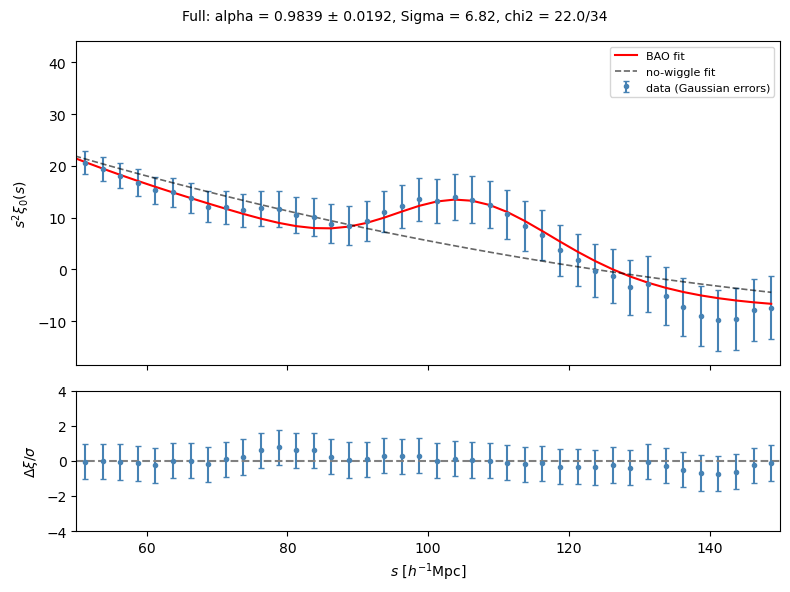


Filament
n_gal = 843846   nbar = 8.438e-04   b (below-BAO) = 1.239 [1.239-1.291]   broadband = xu12   fit (50, 150)
covariance: Gaussian with MEASURED P(k)   (sigma / sigma_Poisson-Gaussian = 1.64-1.70)
            cross-check sigma / sigma_standalone(multidark_power) = 0.90-0.92
Sigma_nl theory (pairwise Zel'dovich, Chen+24 eq.9) = 7.67 h^-1 Mpc
  alpha fit  [Sigma ~ N(theory,2)]: alpha = 0.9931 [0.9650, 1.0231]  marg 0.9973 (+0.0363/-0.0323) | Sigma = 7.13 [5.14, 9.15] marg 7.74 (+2.03/-2.01) | chi2 = 22.9/34
  Sigma free [flat 0-16]      : alpha = 0.9790 [0.9585, 1.0031]  marg 1.0000 (+0.0462/-0.0346) | Sigma = 0.00 [nan, 6.78] marg 8.85 (+5.15/-5.88) | chi2 = 21.8/34
  Sigma with alpha = 1 fixed: 3.75 [nan, 9.89]   marg 7.56 (+5.35/-4.84)
  dilate_all cross-check: alpha = 0.9928 ± 0.0290 (dilate_wiggle ± 0.0291; much smaller => smooth shape is driving alpha)
  BAO detection: Delta chi2 (no-wiggle - BAO) = 8.6; null-mock p = 0.000
  mocks (alpha fit): bias -0.0023, std(alpha_hat) 0

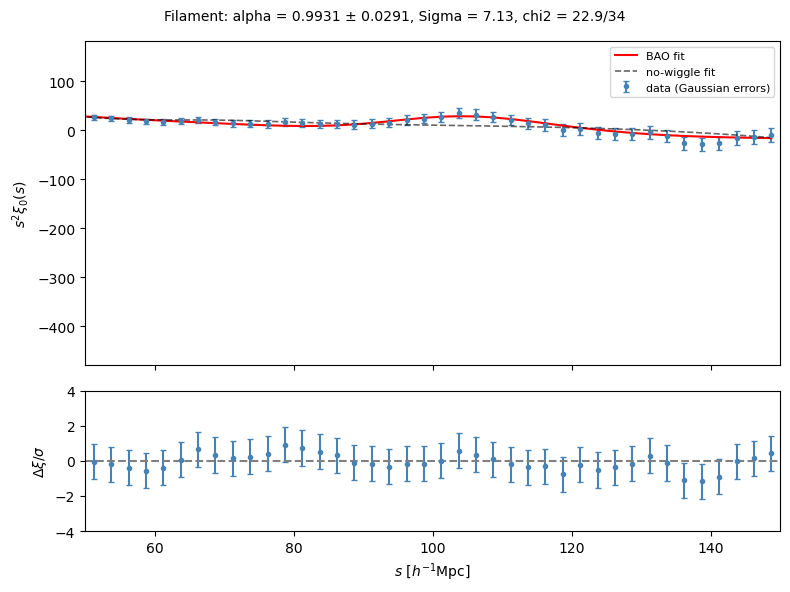

WARNING bias estimate unstable across ranges: (30, 60): 0.682, (40, 70): 0.802, (35, 75): 0.750  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 at k < 0.08

Non-filament
n_gal = 1003482   nbar = 1.003e-03   b (below-BAO) = 0.802 [0.682-0.802]   broadband = xu12   fit (50, 150)
covariance: Gaussian with MEASURED P(k)   (sigma / sigma_Poisson-Gaussian = 1.19-1.20)
            cross-check sigma / sigma_standalone(multidark_power) = 0.89-1.08   <-- WARNING: > 10% off, check b
Sigma_nl theory (pairwise Zel'dovich, Chen+24 eq.9) = 7.67 h^-1 Mpc
  alpha fit  [Sigma ~ N(theory,2)]: alpha = 0.9397 [nan, nan]  marg 0.9976 (+0.1374/-0.1179) | Sigma = 7.68 [5.67, 9.69] marg 8.06 (+2.01/-2.02) | chi2 = 20.0/34
  Sigma free [flat 0-16]      : alpha = 0.9694 [0.8073, nan]  marg 1.0005 (+0.1339/-0.1214) | Sigma = 12.08 [nan, nan] marg 10.73 (+3.85/-6.28) | chi2 = 20.0/34
  Sigma with alpha = 1 fixed: 13.39 [nan, nan]   marg 11.17 (+3.50/-6.03)
  dilate_all cross-check: alpha = 0

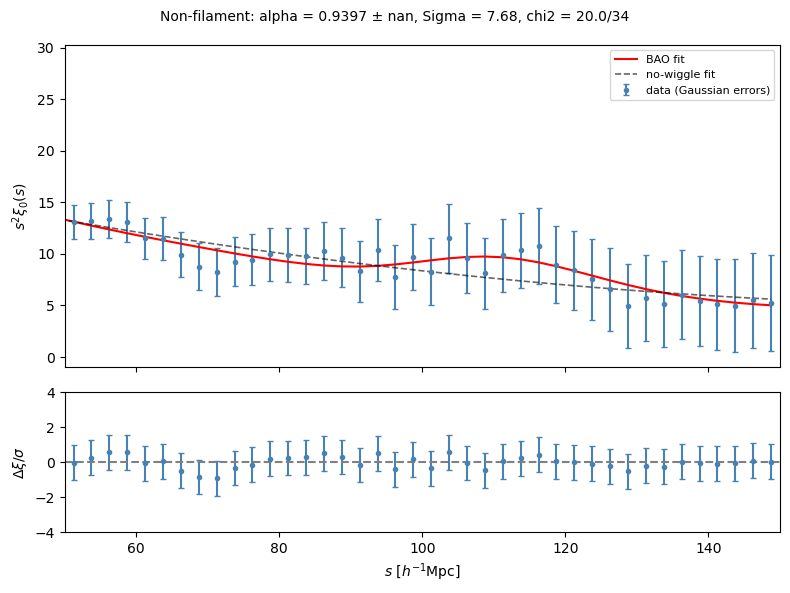


------------------------------------------------------------------------------------------------------------
 SUMMARY   alpha: Sigma ~ N(7.67, 2)    Sigma: flat prior, alpha marginalised
------------------------------------------------------------------------------------------------------------
sample             n_gal     b    alpha     +/-  <Sigma>   +/-  <Sigma>(a=1)  chi2/dof det dchi2
Full             2400560  1.05   0.9839  0.0233     7.49  4.22     7.30 ± 4.15  22.0/34       15.7
Filament          843846  1.24   0.9931  0.0424     8.59  4.66     7.73 ± 4.39  22.9/34        8.6
Non-filament     1003482  0.80   0.9397  0.1103     9.86  4.45    10.23 ± 4.30  20.0/34        1.0
alpha +/- = marginal posterior std (better coverage than Delta-chi2 = 1, see mocks); <Sigma> = marginal posterior mean +/- std
------------------------------------------------------------------------------------------------------------
Differences (alpha fit; correlated Gaussian mocks of the same box, n = 40

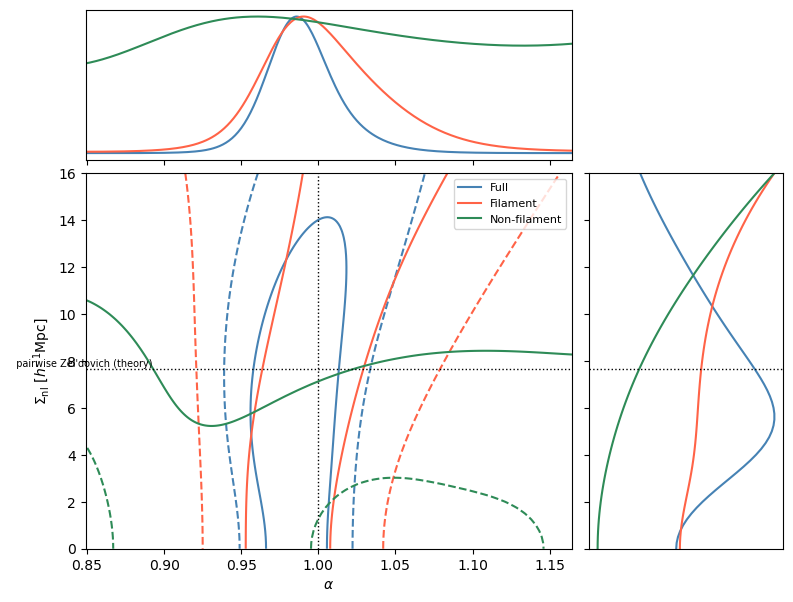

In [17]:
# ---- REAL ANALYSIS -----------------------------------------------------------
# Standard analysis for every subsample: xi_0 + Gaussian covariance from the MEASURED P(k)
# -> alpha, Sigma, B^2, detection Delta chi^2 and null-mock p.  Differences between subsamples
# use joint mocks (the subsamples share the box, so their errors are correlated).
binsep = 2.5      # must match bin_size_2d used in multidark_analysis.py.
                  # 2.5 and 3 give the same sigma(alpha) and sigma(Sigma) (Fisher test, 2026-10-16);
                  # 5 loses ~15% on sigma(Sigma) for the filament sample.  The covariance treats
                  # shot noise analytically, so it is exact for any bin width.
base = f'../data/monopoles/box/mag=-21.2_sep=5.0-150.0_binsep={binsep:.1f}_'
samples = {
    'Full':         base + 'full.npz',
    'Filament':     base + '0.0-d_mathrmfilleq5.0.npz',
    'Non-filament': base + '10.0-d_mathrmfilleq100.0.npz',
    # Add the new subsamples here, with the file suffix multidark_analysis.py writes, e.g.
    # 'Fil dense':        base + '<bin_desc>.npz',
    # 'Fil underdense':   base + '<bin_desc>.npz',
    # 'NonFil dense':     base + '<bin_desc>.npz',
    # 'NonFil underdense':base + '<bin_desc>.npz',
    # 'Full dil. nFil':   base + '<bin_desc>.npz',
    # 'Full dil. nNonFil':base + '<bin_desc>.npz',
    # Every sample needs its spectrum in pk_file (same label), so measure_spectra must include it.
}
# spectra written by multidark_analysis.py (multidark_power.measure_spectra); None -> Poisson Gaussian
pk_file = '../data/pk/box/pk_XISMU_box_mag-21.2_dist_fil.npz'

# Comparisons to report (decide these before looking at the new results)
pairs = [('Filament', 'Non-filament'), ('Filament', 'Full'), ('Non-filament', 'Full'),
         # ('Fil dense', 'NonFil dense'), ('Fil underdense', 'NonFil underdense'),
         # ('Filament', 'Full dil. nFil'),
        ]
res = run_all(samples, pk_file=pk_file, pairs=pairs,
              fit_range=(50, 150), broadband='xu12', n_mock=300, n_mock_diff=400)

# Optional, model-independent shape check (window 95-115 is centred on the theory BAO peak):
# shape_FF = compare_shapes(res, 'Filament', 'Full', window=(95, 115))

# Robustness (appendix): the differences between subsamples should not move.
# run_all(samples, pk_file=pk_file, pairs=pairs, dewiggle='gauss', plot=False, n_mock=100)
# for bb in ('chen24', 'xu12_poly2', 'xu12_poly4'):
#     run_all(samples, pk_file=pk_file, pairs=pairs, broadband=bb, plot=False, n_mock=100)
# for fr in ((40, 150), (60, 150)):
#     run_all(samples, pk_file=pk_file, pairs=pairs, fit_range=fr, plot=False, n_mock=100)

## 12. Methods table: literature choice / our choice / test

| Choice | Xu+12 | Chen+24 (DESI) | This pipeline | Test here | Referee risk |
|---|---|---|---|---|---|
| Statistic | ξ₀(s), recon & pre-recon | P_ℓ and ξ_ℓ, post-recon | ξ₀(s), pre-recon, real space | — | Pre-recon α carries a non-linear shift (Chen §3); fine for *relative* comparisons |
| Template split | Eisenstein–Hu no-wiggle | Wallisch (2018); 5 methods ≤0.02 % | Wallisch (default); Gaussian filter as alternative | V0; `dewiggle=` option | Low; **high for Σ** if a poor split is used |
| High-k treatment | e^{−k²a²}, a = 1 | Fourier-space model | taper on smooth part only; bin-averaged | V1, V3 | Low (fixed) |
| Damping | Σ fixed (8 pre-recon) | Gaussian prior, width 1–2 | N(7.67, 2) for α; flat for Σ | V2, V3 | Must justify prior centre: Chen eq. 9 |
| Dilation | whole template | wiggle only | wiggle only (+ whole-template cross-check) | V4 | Low |
| Broadband | a₁/r² + a₂/r + a₃ | splines (≡ r_min cut + a₀ + a₁r² in ξ₀) | Xu default; Chen, poly2, poly4 options | §11 robustness block | Show ΔΔα, ΔΣ stable |
| Linear params | nested linear fit | analytic marginalisation (App. F) | exact GLS, profile + marginal | V2 | Low |
| Priors | log B² ~ N(0, 0.4); 15 % on log α | flat b, β | B² ≥ 0; α ∈ [0.8, 1.2] | V2 | State α range |
| Covariance | Gaussian + 4 params fit to 160 mocks | 1000 EZmocks | Gaussian with measured auto/cross P(k), lattice modes, V = L³ | V6; χ² per sample | **High**: no connected (trispectrum) term; validate with independent realisations |
| Fit range | 30–200 | 50–150 (ξ) | 50–150 | robustness block | Low |
| Error validation | 160 mocks, pull distribution | 25 CV mocks | Gaussian mocks (machinery only) | V2 | Medium |
| Sample differences | — | — | joint covariance + correlated mocks, null p | V5 | Without this, errors on differences are wrong |
| Systematics budget | — | Table 1: ≤ 0.1 % α_iso | vary each choice, report shift in Δα, ΔΣ | §11 block | Needed |

## 13. Next steps, in priority order

1. **Rerun `multidark_analysis.py`** (writes the spectra and prints the slab counts), then §11 with `pk_file`. Look at each sample's χ²/dof first, then σ(Δα) and σ(ΔΣ) for Filament − Non-filament.
2. **Matched controls.** Random subsamples of Full with the same N as Filament (and as Non-filament), ideally also matched in bias. Compute their monopoles and spectra and add them to `samples`. "Filament BAO is better" only means something relative to these, because σ_α and the detection Δχ² depend on n̄ and b² alone. Several random draws give the spread.
3. **The 2×2 split** (filament/non-filament × dense/non-dense ρ₃): compare filament vs non-filament at fixed ρ₃ and matched bias.
4. **Measure the damping directly** (ESW07 §6–7): for galaxy pairs now separated by 90–110 h⁻¹Mpc, take the rms change in separation since high z, using each galaxy's main-progenitor halo at z ≳ 3 as its initial position. Do it per sample.
5. **Robustness table** (Chen+24 style): `broadband` ∈ {xu12, chen24, poly2, poly4}, fit ranges {40, 50, 60}–150, `dewiggle='gauss'`. Report the shift in Δα and ΔΣ.
6. **Covariance validation for the paper:** independent realisations or fast mocks with the same selection. The measured-P(k) covariance has no connected (trispectrum) term.
7. **Keep in mind (not testable now):** filaments were found by DisPerSE on the same galaxies that are then selected. Selecting galaxies near structures defined by themselves can add noise and spurious structure. A split-half test (filaments from one random half, galaxies from the other) would settle it if your colleague can run it later.
8. Confirm `Z_SNAP`, `REAL_SPACE` and `COSMO`. If positions include RSD, set `REAL_SPACE=False` and pass the bias to `sigma_nl_theory`.